# Import

In [2]:
from pathlib import Path
from math import factorial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tikzplotlib

# Results directory

In [3]:
# RESULTS_DIR = Path("results/test_Mcp_14")
RESULTS_DIR = Path("results/accept_SRMP")

# File

In [4]:
DATA = RESULTS_DIR / "compromise_results.csv"
MIE = RESULTS_DIR / "mie_results.csv"
COLLECTIVE = RESULTS_DIR / "collective_results.csv"
PATH = RESULTS_DIR / "path_results.csv"
DISTANCE = RESULTS_DIR / "distance.csv"

# Read files

In [5]:
df = pd.read_csv(DATA)
df_mie = pd.read_csv(MIE)
df_collective = pd.read_csv(COLLECTIVE)
df_path = pd.read_csv(PATH)
df_distance = pd.read_csv(DISTANCE)

In [6]:
# dfs = []
# dfs_collective = []
# dfs_path = []
# dfs_distance = []

# for M in [3, 4, 5]:
#     for K in [1, 2, 3]:
#         RESULTS_DIR = Path(f"results/Mcp_M_{M}_K_{K}")

#         DATA = RESULTS_DIR / "compromise_results.csv"
#         COLLECTIVE = RESULTS_DIR / "collective_results.csv"
#         PATH = RESULTS_DIR / "path_results.csv"
#         DISTANCE = RESULTS_DIR / "distance.csv"

#         dfs.append(pd.read_csv(DATA))
#         100
#         dfs_collective.append(pd.read_csv(COLLECTIVE))
#         500
#         dfs_path.append(pd.read_csv(PATH))
#         1000
#         dfs_distance.append(pd.read_csv(DISTANCE))
#         2000

# df = pd.concat(dfs)
# df_collective = pd.concat(dfs_collective)
# df_path = pd.concat(dfs_path)
# df_distance = pd.concat(dfs_distance)

In [7]:
# df

In [8]:
# df_collective

In [9]:
# df_path

In [10]:
# df_distance

<!-- # Correction -->

In [11]:
# df_collective["Objective"] = df_collective["Objective"] % df_collective["N_bc"]

# Group by

In [12]:
df_mie = df_mie.set_index([
        "M",
        "N_tr",
        "Atr_id",
        "Model",
        "Ko",
        "Mo_id",
        "Group_size",
        "Group",
        "Mi_id",
        "N_bc",
        "Same_alt",
        "D_id",
        "Config",
        # "Method",
    ])
df_mie = df_mie.rename(columns={"Optimal": "Mie"})

df = df.join(
    df_mie["Mie"],
    on=[
        "M",
        "N_tr",
        "Atr_id",
        "Model",
        "Ko",
        "Mo_id",
        "Group_size",
        "Group",
        "Mi_id",
        "N_bc",
        "Same_alt",
        "D_id",
        "Config",
        # "Method",
    ],
)
df

,M,N_tr,Atr_id,Model,Ko,Mo_id,Group_size,Group,Mi_id,N_bc,...,Config,Mc_id,Nb_Mcp,Path,P_id,Compromise,Time,It,Changes,Mie
0,3,100,2,SRMP,1,2,2,0,2,10,...,0,2,1,True,2,True,1.546324,1,1,True
1,3,100,0,SRMP,1,0,2,0,0,10,...,0,0,1,True,0,True,1.695522,1,1,True
2,3,100,7,SRMP,1,7,2,0,7,10,...,0,7,1,True,7,True,1.439989,1,4,True
3,3,100,6,SRMP,1,6,2,0,6,10,...,0,6,1,True,6,True,2.467443,1,3,True
4,3,100,7,SRMP,1,7,2,0,7,20,...,0,7,1,True,7,True,1.612624,1,0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4149,7,100,5,SRMP,1,5,6,3,5,30,...,0,5,1,True,5,False,923.292714,3,0,False
4150,7,100,4,SRMP,1,4,6,3,4,30,...,0,4,1,True,4,False,970.306855,4,0,False
4151,7,100,1,SRMP,1,1,6,3,1,50,...,0,1,1,True,1,False,120.641184,1,0,False
4152,7,100,6,SRMP,1,6,6,3,6,30,...,0,6,1,True,6,False,957.951078,4,0,False


In [13]:
df_collective["Objective"] = df_collective["Objective"].astype("float64")

df_collective_b = df_collective[df_collective["Group_size"] == 2]
df_collective_b["Group_size"] = 6
df_collective_b["Objective"] = df_collective_b["Objective"] * 2
df_collective_b.loc[df_collective_b["Ko"] == 1, "Objective"] = (
    df_collective_b.loc[df_collective_b["Ko"] == 1, "Objective"] * 1.1
)
df_collective_b.loc[df_collective_b["Ko"] == 2, "Objective"] = (
    df_collective_b.loc[df_collective_b["Ko"] == 2, "Objective"] * 1.1
)

df_collective = pd.concat([df_collective, df_collective_b])

In [14]:
df_collective_exp = df_collective.groupby(
    by=[
        "M",
        "N_tr",
        "Atr_id",
        "Model",
        "Ko",
        "Mo_id",
        "Group_size",
        "Group",
        "Mi_id",
        "N_bc",
        "Same_alt",
        "D_id",
        "Method",
        "Config",
        "Mc_id",
        "Nb_Mcp",
        "Path",
        "P_id",
    ],
    as_index=False,
).mean()
df_collective_exp

,M,N_tr,Atr_id,Model,Ko,Mo_id,Group_size,Group,Mi_id,N_bc,...,Method,Config,Mc_id,Nb_Mcp,Path,P_id,It,Time,Objective,Optimal
0,3,100,0,SRMP,1,0,2,0,0,10,...,MIP,0,0,1,True,0,0.00,0.117419,1.000000,1.0
1,3,100,0,SRMP,1,0,2,0,0,20,...,MIP,0,0,1,True,0,0.50,0.132786,3.000000,1.0
2,3,100,0,SRMP,1,0,2,0,0,30,...,MIP,0,0,1,True,0,0.00,0.172054,1.000000,1.0
3,3,100,0,SRMP,1,0,2,0,0,40,...,MIP,0,0,1,True,0,1.00,0.465173,4.333333,1.0
4,3,100,0,SRMP,1,0,2,0,0,50,...,MIP,0,0,1,True,0,0.50,0.448340,4.000000,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4195,7,100,9,SRMP,1,9,6,3,9,10,...,MIP,0,9,1,True,9,1.20,0.190946,3.440000,1.0
4196,7,100,9,SRMP,1,9,6,3,9,20,...,MIP,0,9,1,True,9,0.75,2.139248,7.400000,1.0
4197,7,100,9,SRMP,1,9,6,3,9,30,...,MIP,0,9,1,True,9,0.75,2.790547,11.900000,1.0
4198,7,100,9,SRMP,1,9,6,3,9,40,...,MIP,0,9,1,True,9,0.50,5.490215,11.350000,1.0


# New attributes

In [15]:
# df["Gen"] = np.array(["Homogene", "Heterogene"])[df["Group"] % 2]
# df["Accept"] = np.array(["Conservative", "Tolerant"])[df["Group"] % 2]

df["Changes_Mean"] = df["Changes"] / df["Group_size"]
df["Changes_Prop"] = df["Changes"] / (df["N_bc"] * df["Group_size"])

df_collective_exp["Objective_Prop"] = (
    df_collective_exp["Objective"] / df_collective_exp["N_bc"]
)
df_collective_exp["Time"] /= df_collective_exp["Ko"].apply(factorial)

df["Time_Per_It"] = df["Time"] / df["It"]

df["It_Nbc"] = df["It"] / df["N_bc"]

In [16]:
# from math import inf


# df_collective.loc[df_collective["Objective"] == inf, "Time"] = 600

# Filter

In [17]:
# dff = df[df["Fitness_train"] == 1]
# dff = df[df["N_tr"].isin([10, 20, 30, 80, 90, 100])]
# dff = df[df["N_tr"] % 20 == 0]
dff = df
# dff = dff[~df["Mie"]]
# dff = dff.drop(columns=["Mie", "Mie_id"])
# dff = dff[dff["Group_size"] == 2]
# dff = dff[dff["M"] <= 4]
# dff = dff[dff["Ko"] <= 3]
# dff = dff[dff["Group_size"] <= 2]
# dff = dff[dff["Gen"] == "Homogene"]
# dff = dff[dff["Path"]]
# dff = dff[dff["Compromise"]]
# dff = dff[dff["Time"] < 3600]
# dff = dff[dff["It"] < 2 * dff["N_bc"]]
# df_collective = df_collective[df_collective["It"] < 2 * df_collective["N_bc"]]
# dff = dff[dff["Time_Per_It"] < 600]
# dff["Time_Per_It"] = dff["Time_Per_It"] / 2

In [18]:
dff

,M,N_tr,Atr_id,Model,Ko,Mo_id,Group_size,Group,Mi_id,N_bc,...,P_id,Compromise,Time,It,Changes,Mie,Changes_Mean,Changes_Prop,Time_Per_It,It_Nbc
0,3,100,2,SRMP,1,2,2,0,2,10,...,2,True,1.546324,1,1,True,0.5,0.05,1.546324,0.100000
1,3,100,0,SRMP,1,0,2,0,0,10,...,0,True,1.695522,1,1,True,0.5,0.05,1.695522,0.100000
2,3,100,7,SRMP,1,7,2,0,7,10,...,7,True,1.439989,1,4,True,2.0,0.20,1.439989,0.100000
3,3,100,6,SRMP,1,6,2,0,6,10,...,6,True,2.467443,1,3,True,1.5,0.15,2.467443,0.100000
4,3,100,7,SRMP,1,7,2,0,7,20,...,7,True,1.612624,1,0,True,0.0,0.00,1.612624,0.050000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4149,7,100,5,SRMP,1,5,6,3,5,30,...,5,False,923.292714,3,0,False,0.0,0.00,307.764238,0.100000
4150,7,100,4,SRMP,1,4,6,3,4,30,...,4,False,970.306855,4,0,False,0.0,0.00,242.576714,0.133333
4151,7,100,1,SRMP,1,1,6,3,1,50,...,1,False,120.641184,1,0,False,0.0,0.00,120.641184,0.020000
4152,7,100,6,SRMP,1,6,6,3,6,30,...,6,False,957.951078,4,0,False,0.0,0.00,239.487770,0.133333


# Merge data

In [19]:
if not dff["Path"].all():
    # df = pd.merge(
    #     df_mip,
    #     df_path,
    #     how="left",
    #     on=[
    #         "M",
    #         "N_tr",
    #         "Atr_id",
    #         "Ko",
    #         "Mo_id",
    #         "Group_size",
    #         "Group",
    #         "Mi_id",
    #         "N_bc",
    #         "Same_alt",
    #         "D_id",
    #         "Config",
    #         "Mc_id",
    #         "Path",
    #         "P_id",
    #         "It"
    #     ],
    #     suffixes=["_mip", "_path"],
    # )

    df_compromise_path = dff[dff["Path"]]
    df_compromise_path = df_compromise_path[df_compromise_path["Compromise"]]
    df_compromise_path_index = df_compromise_path.drop(
        columns=["Path", "Compromise", "Time", "It", "Changes", "Changes_Prop"]
    )
    df_compromise_no_path = dff[~dff["Path"]]
    df_compromise_no_path = df_compromise_no_path[df_compromise_no_path["Compromise"]]
    df_compromise_no_path_index = df_compromise_no_path.drop(
        columns=["Path", "Compromise", "Time", "It", "Changes", "Changes_Prop"]
    )

    df_compromise_index = pd.merge(
        df_compromise_path_index,
        df_compromise_no_path_index,
        how="inner",
        on=[
            "M",
            "N_tr",
            "Atr_id",
            "Model",
            "Ko",
            "Mo_id",
            "Group_size",
            "Group",
            "Mi_id",
            "N_bc",
            "Same_alt",
            "D_id",
            "Config",
            "P_id",
            "Nb_Mcp",
            "Mc_id",
            "P_id",
            # "Gen",
            # "Accept",
        ],
    )

    df_compromise_path = pd.merge(
        df_compromise_path,
        df_compromise_index,
        how="inner",
        on=[
            "M",
            "N_tr",
            "Atr_id",
            "Model",
            "Ko",
            "Mo_id",
            "Group_size",
            "Group",
            "Mi_id",
            "N_bc",
            "Same_alt",
            "D_id",
            "Config",
            "P_id",
            "Nb_Mcp",
            "Mc_id",
            "P_id",
            # "Gen",
            # "Accept",
        ],
        suffixes=["", ""],
    )

    df_compromise_no_path = pd.merge(
        df_compromise_no_path,
        df_compromise_index,
        how="inner",
        on=[
            "M",
            "N_tr",
            "Atr_id",
            "Model",
            "Ko",
            "Mo_id",
            "Group_size",
            "Group",
            "Mi_id",
            "N_bc",
            "Same_alt",
            "D_id",
            "Config",
            "P_id",
            "Nb_Mcp",
            "Mc_id",
            "P_id",
            # "Gen",
            # "Accept",
        ],
        suffixes=["", ""],
    )

    # df_compromise = pd.merge(
    #     df_compromise_path,
    #     df_compromise_no_path,
    #     how="inner",
    #     on=[
    #         "M",
    #         "N_tr",
    #         "Atr_id",
    #         "Ko",
    #         "Mo_id",
    #         "Group_size",
    #         "Group",
    #         "Mi_id",
    #         "N_bc",
    #         "Same_alt",
    #         "D_id",
    #         "Config",
    #         "Mie",
    #         "P_id",
    #         "Mie_id",
    #         "Mc_id",
    #         "P_id",
    #         "Gen",
    #         "Accept"
    #     ],
    #     suffixes=["_path", "_no_path"],
    # )

    df_compromise = pd.concat([df_compromise_path, df_compromise_no_path])

    df_compromise

# Plot

## Compromise

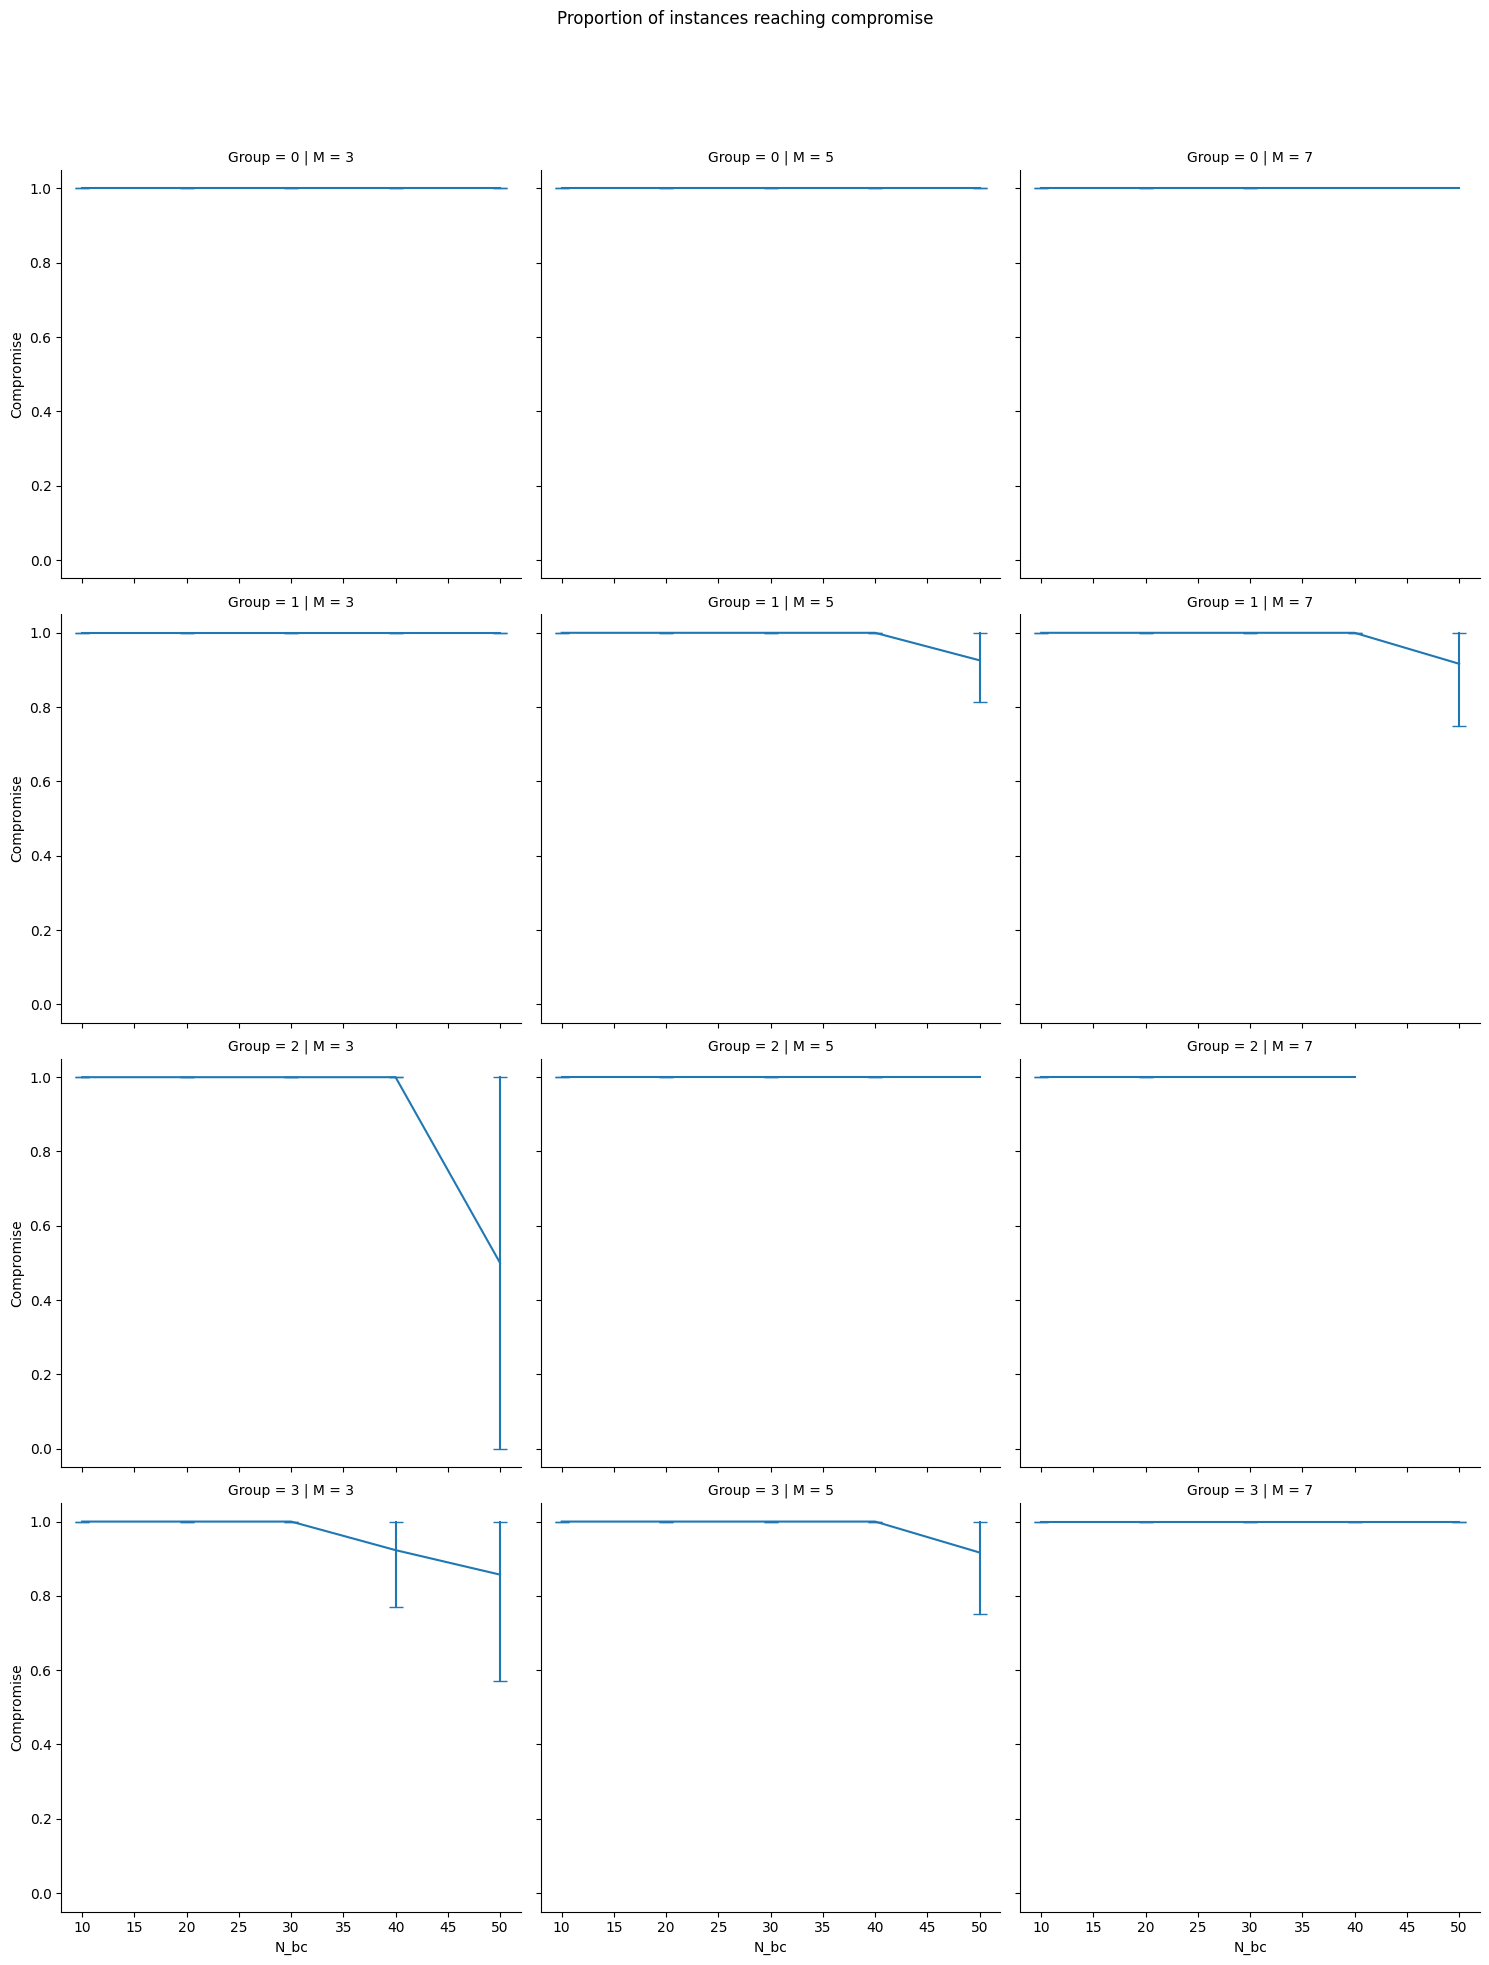

In [ ]:
g = sns.relplot(
    # dff[(dff["Group"] == "Homo") & (~dff["Path"])],
    dff[dff["Mie"]],
    x="N_bc",
    y="Compromise",
    col="M",
    # row="Group",
    # style="Nb_Mcp",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Proportion of instances reaching compromise")
g

tikzplotlib.save("mytikz.tex", standalone=True)

In [19]:
g = sns.relplot(
    dff[~dff["Path"] & (dff["Ko"] == 2)],
    x="N_bc",
    y="Compromise",
    # row="Group",
    col="Group_size",
    style="Group",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Proportion of instances reaching compromise")
g

tikzplotlib.save("mytikz.tex", standalone=True)

TypeError: 'NoneType' object is not iterable

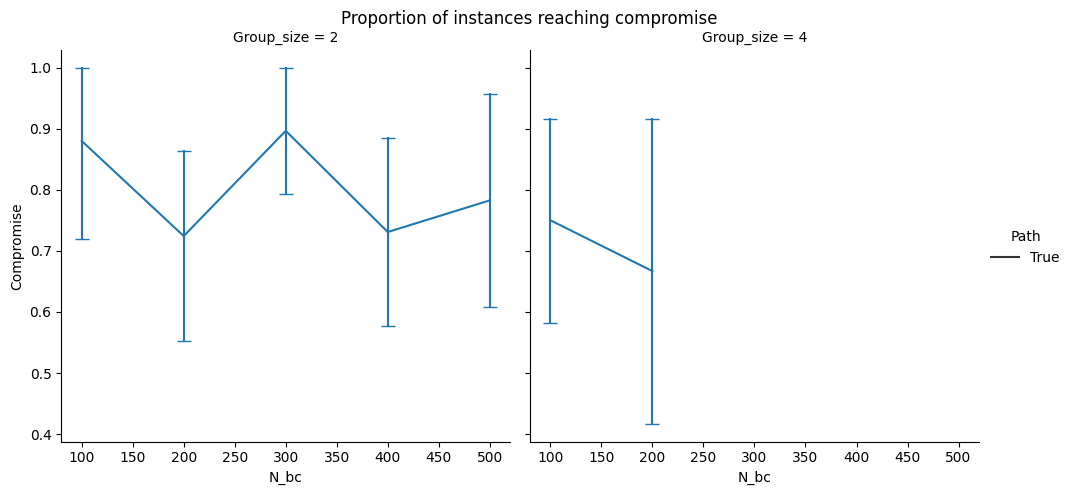

In [ ]:
g = sns.relplot(
    dff,  # dff[(dff["Group"] == "Homo") & (dff["Ko"] == 2)],
    x="N_bc",
    y="Compromise",
    # row="Group",
    col="Group_size",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Proportion of instances reaching compromise")
g

tikzplotlib.save("mytikz.tex", standalone=True)

## Sum of changes

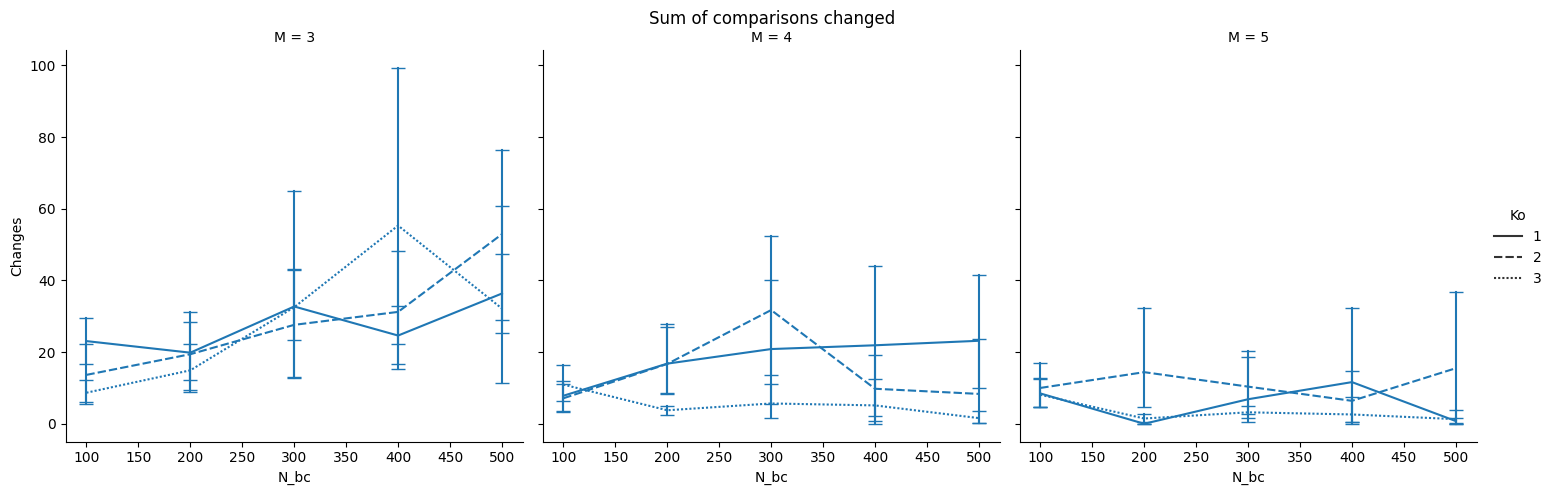

In [ ]:
g = sns.relplot(
    dff,
    x="N_bc",
    y="Changes",
    # row="M",
    col="M",
    style="Ko",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Sum of comparisons changed")
g

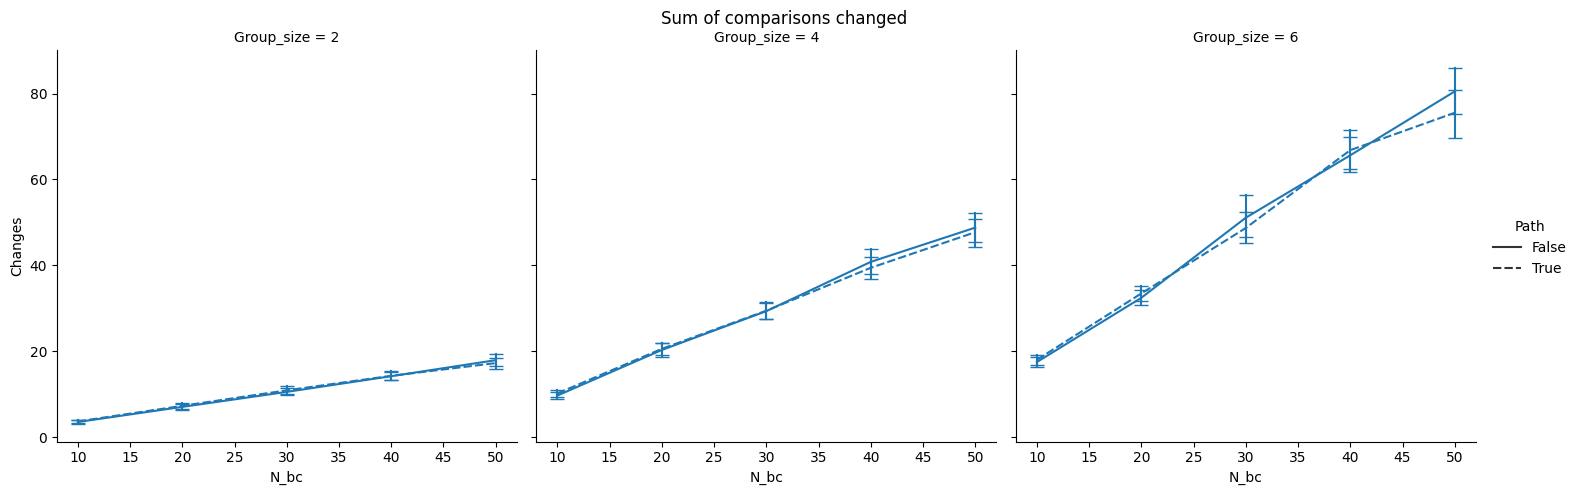

In [ ]:
g = sns.relplot(
    dff,
    x="N_bc",
    y="Changes",
    # row="Group_size",
    col="Group_size",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Sum of comparisons changed")
g

## Mean of changes

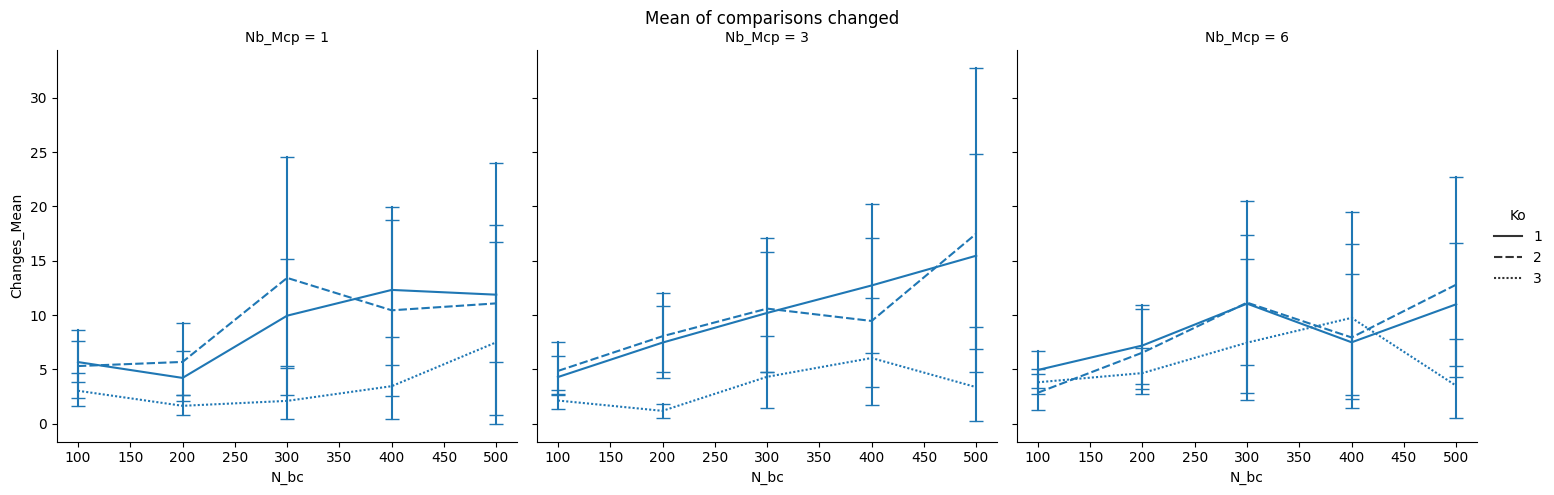

In [ ]:
g = sns.relplot(
    dff,
    x="N_bc",
    y="Changes_Mean",
    # row="M",
    col="Nb_Mcp",
    style="Ko",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Mean of comparisons changed")
g

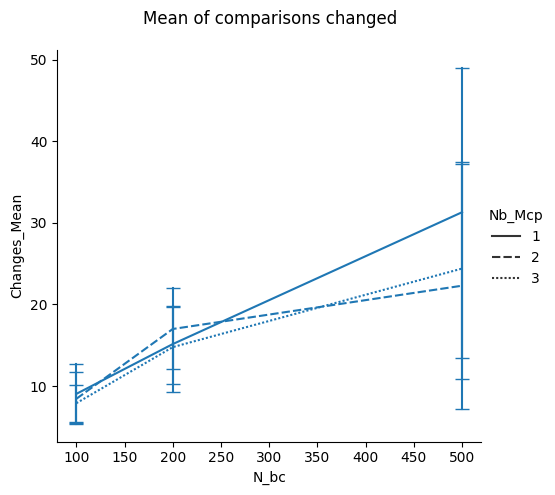

In [ ]:
g = sns.relplot(
    dff[dff["Compromise"]],
    x="N_bc",
    y="Changes_Mean",
    # row="Group_size",
    # col="M",
    style="Nb_Mcp",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Mean of comparisons changed")
g

## Proportion of changes

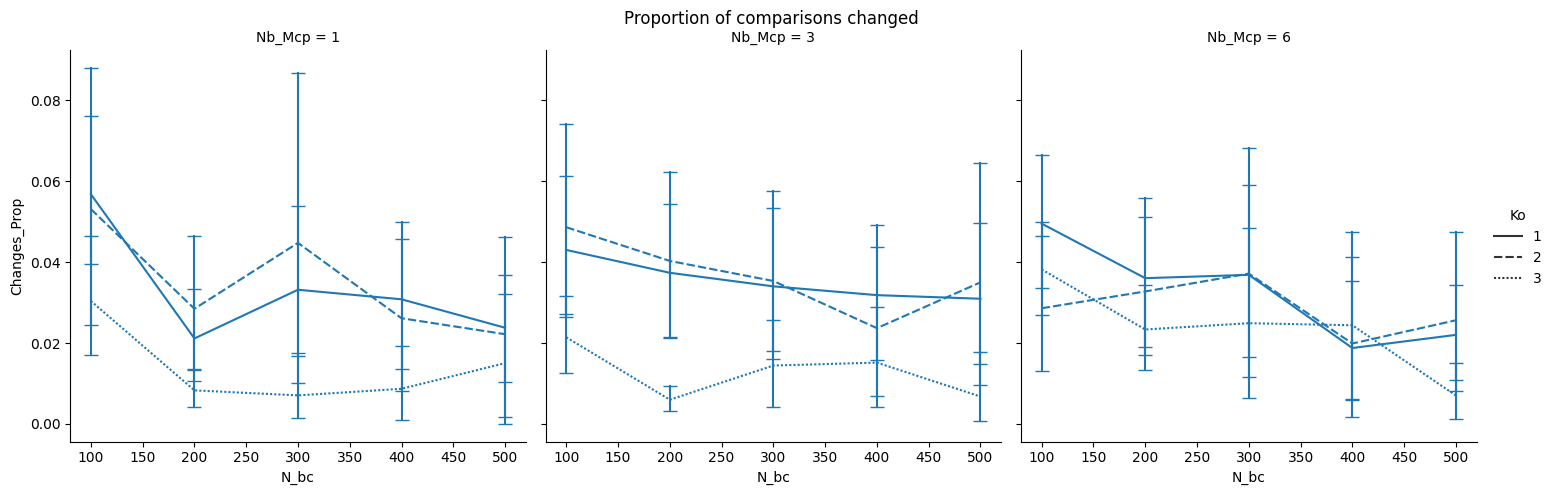

In [ ]:
g = sns.relplot(
    dff,
    x="N_bc",
    y="Changes_Prop",
    # row="M",
    col="Nb_Mcp",
    style="Ko",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Proportion of comparisons changed")
g

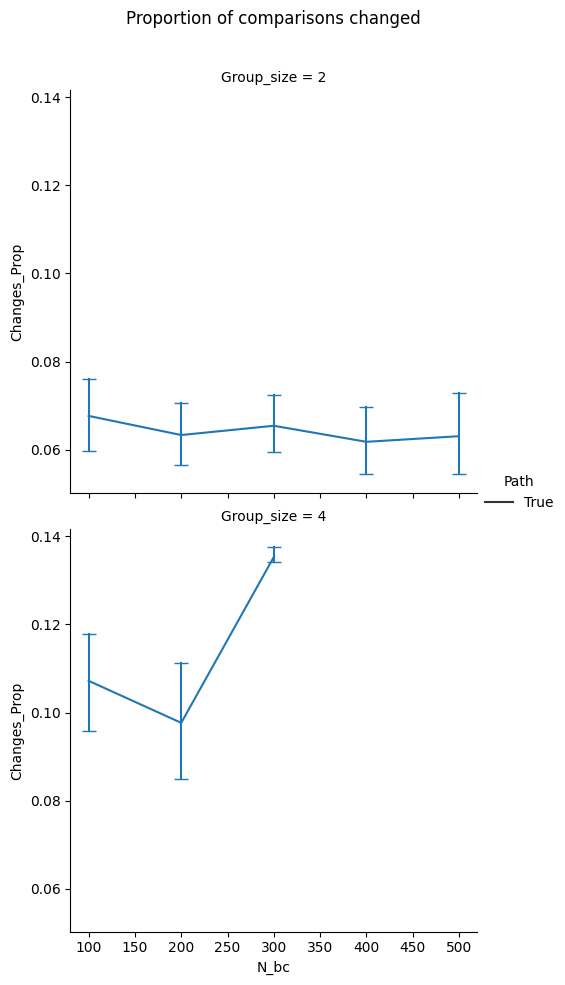

In [ ]:
g = sns.relplot(
    dff[dff["Compromise"]],
    x="N_bc",
    y="Changes_Prop",
    # row="Group_size",
    # col="M",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Proportion of comparisons changed")
g

## MILP / SA objective value

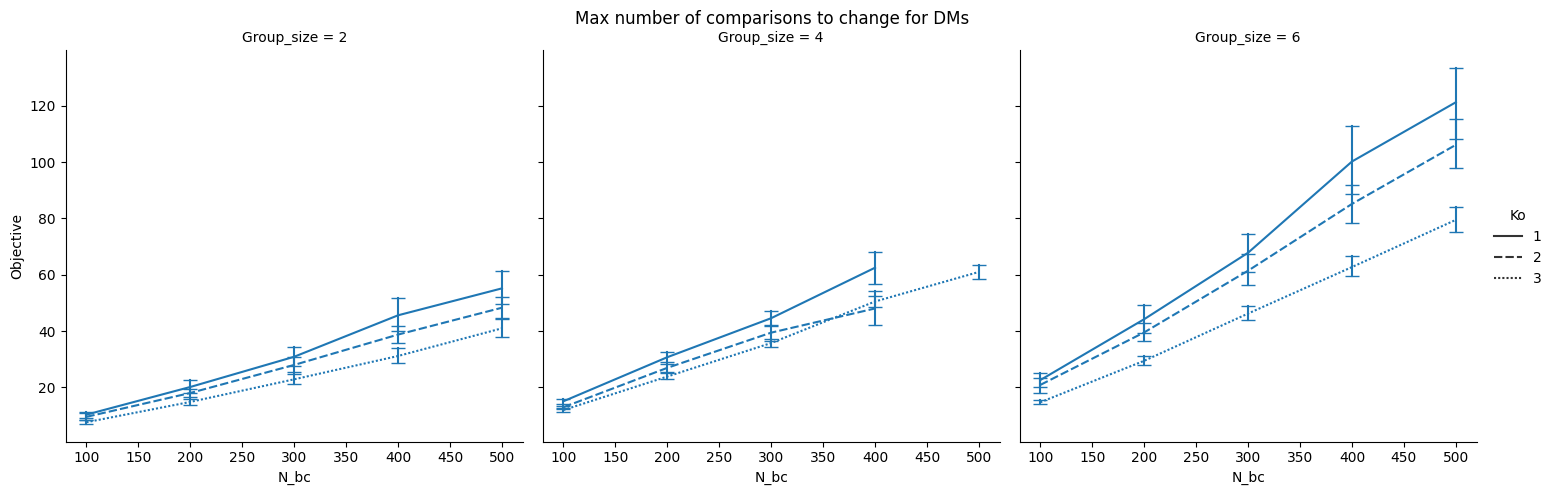

In [ ]:
g = sns.relplot(
    # df_collective_exp[(~df_collective_exp["Path"]) & (df_collective_exp["Group"] == "Homo")],
    df_collective_exp,
    x="N_bc",
    y="Objective",
    # row="M",
    col="Group_size",
    style="Ko",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Max number of comparisons to change for DMs")
g

tikzplotlib.save("mytikz.tex", standalone=True)

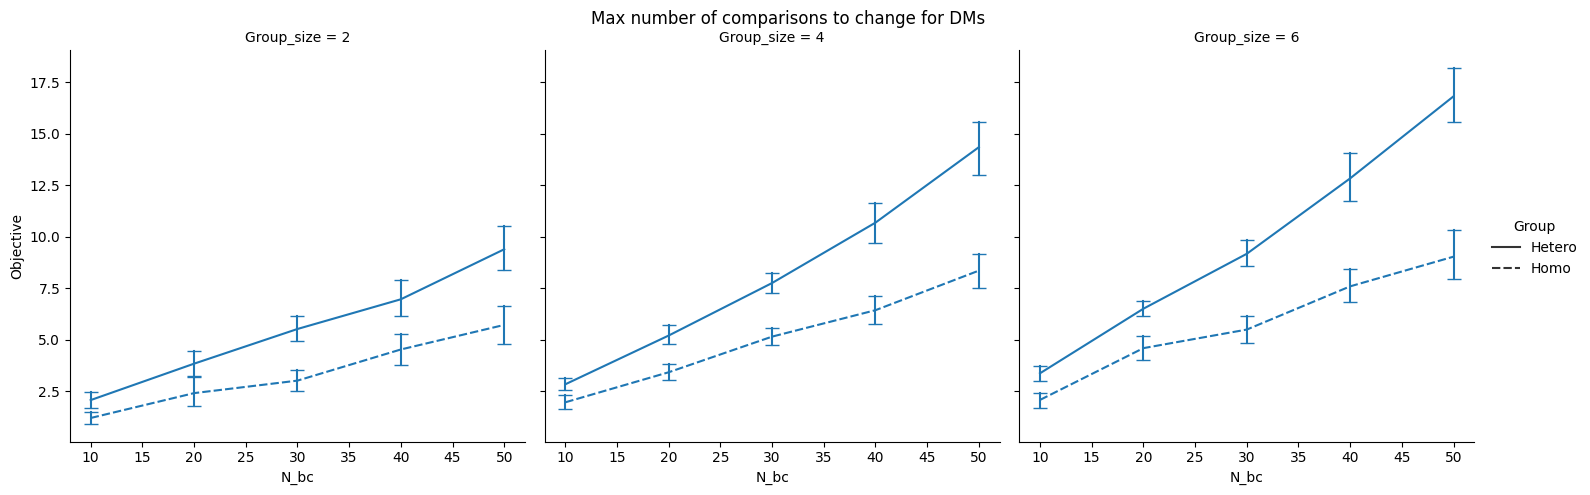

In [ ]:
g = sns.relplot(
    df_collective_exp[(~df_collective_exp["Path"]) & (df_collective_exp["Ko"] == 2)],
    x="N_bc",
    y="Objective",
    # row="Group",
    col="Group_size",
    style="Group",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Max number of comparisons to change for DMs")
g

tikzplotlib.save("mytikz.tex", standalone=True)

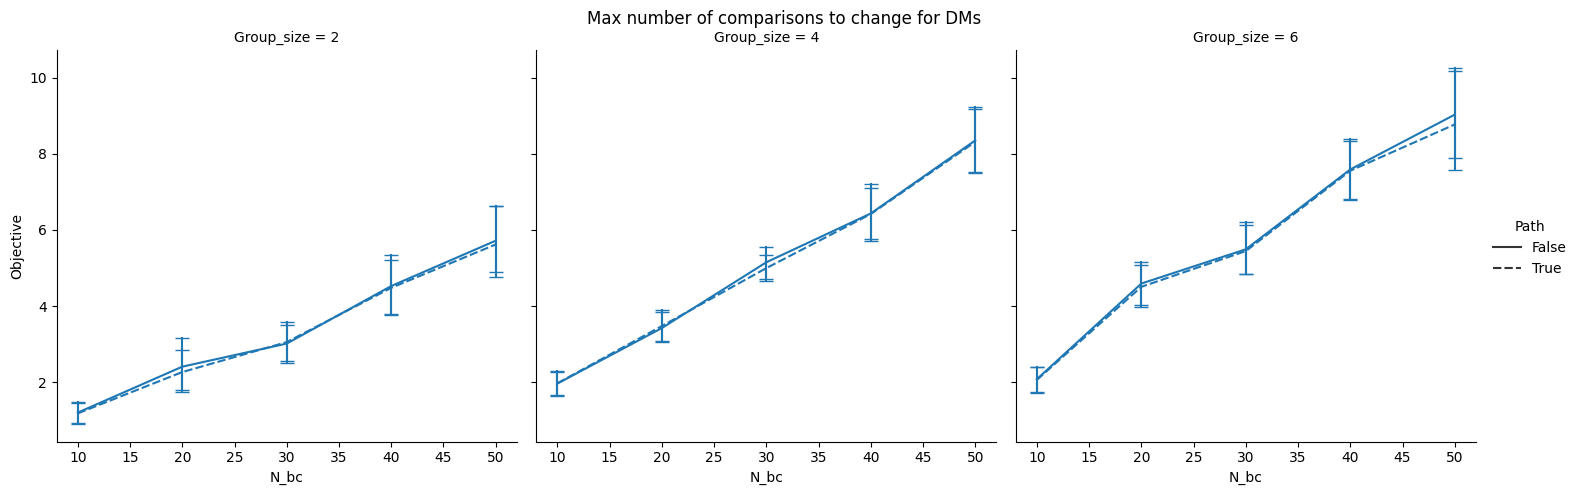

In [ ]:
g = sns.relplot(
    df_collective_exp[
        (df_collective_exp["Group"] == "Homo") & (df_collective_exp["Ko"] == 2)
    ],
    x="N_bc",
    y="Objective",
    col="Group_size",
    # col="M",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Max number of comparisons to change for DMs")
g

tikzplotlib.save("mytikz.tex", standalone=True)

## Proportion MILP / SA objective value

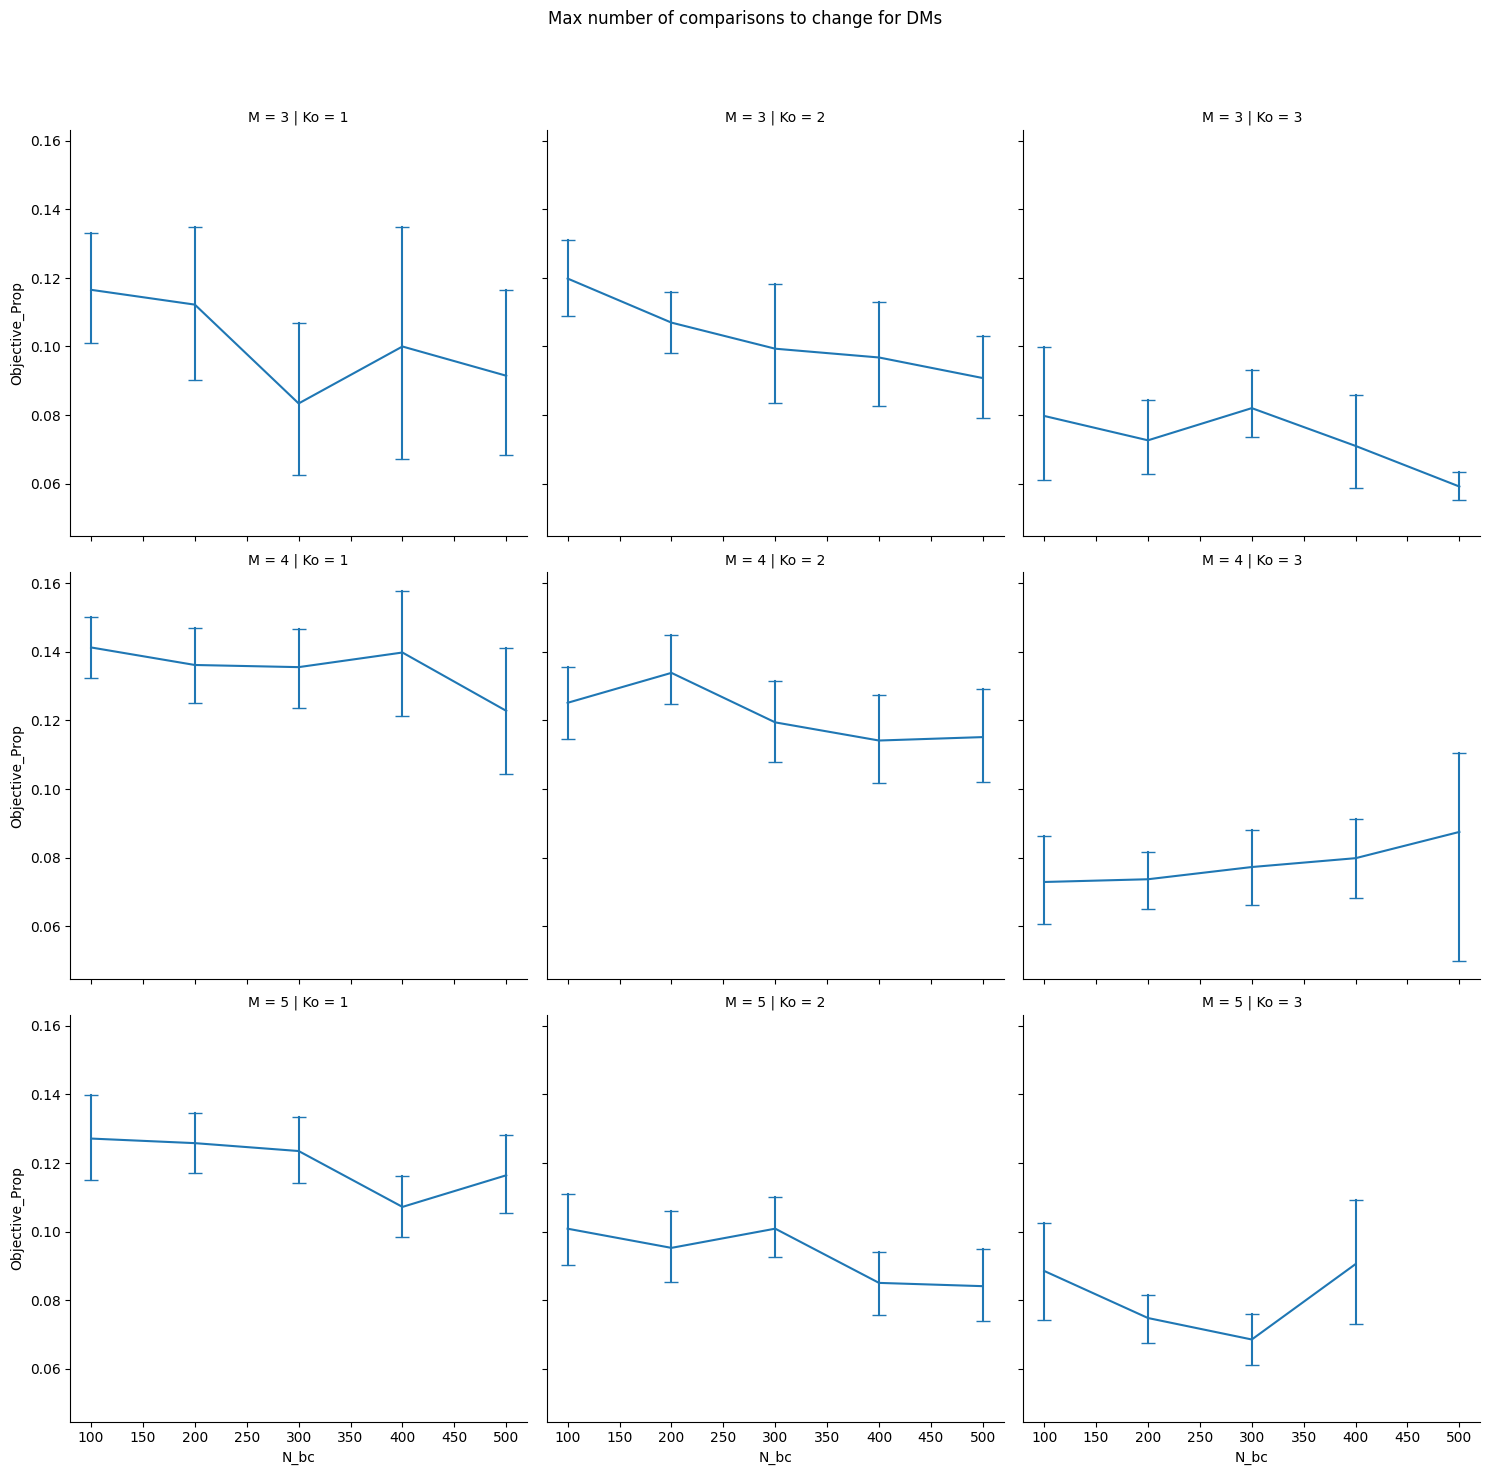

In [ ]:
g = sns.relplot(
    df_collective_exp,
    x="N_bc",
    y="Objective_Prop",
    row="M",
    col="Ko",
    # style="Nb_Mcp",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Max number of comparisons to change for DMs")
g

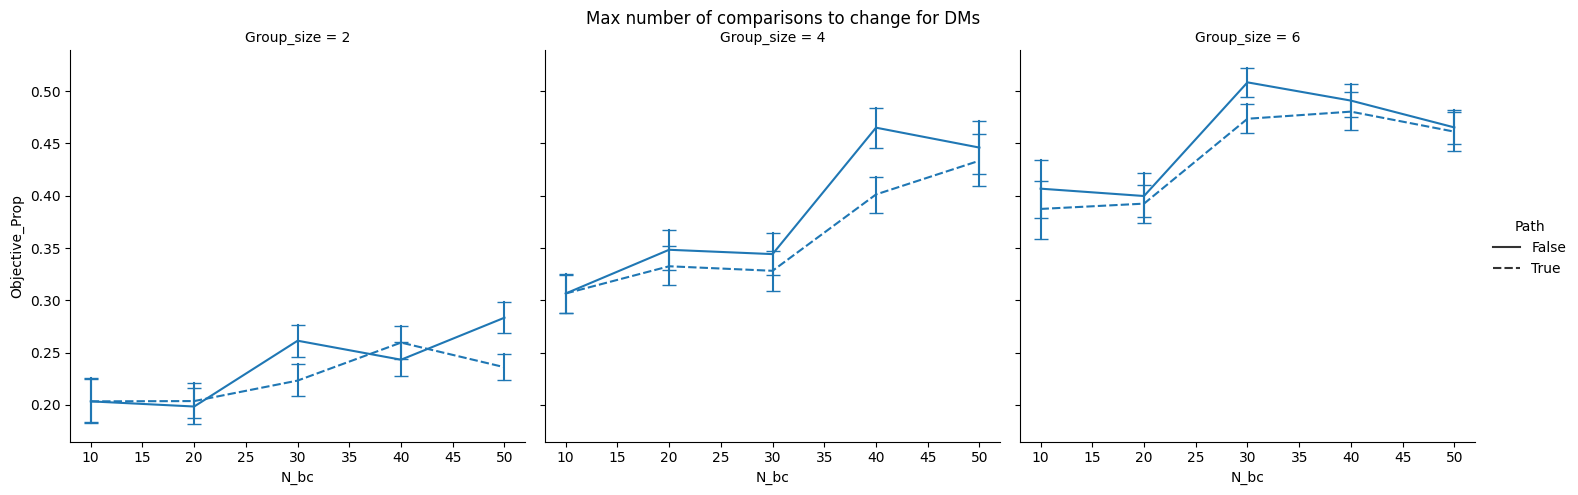

In [ ]:
g = sns.relplot(
    df_collective_exp,
    x="N_bc",
    y="Objective_Prop",
    # row="Group_size",
    col="Group_size",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Max number of comparisons to change for DMs")
g

## MILP / SA optimal

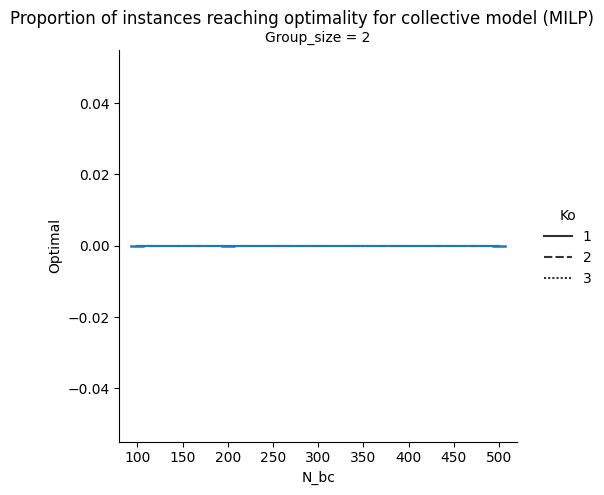

In [ ]:
g = sns.relplot(
    df_collective,
    x="N_bc",
    y=df_collective["Optimal"],
    col="Group_size",
    # row="Group_size",
    style="Ko",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle(
    "Proportion of instances reaching optimality for collective model (MILP)"
)
g

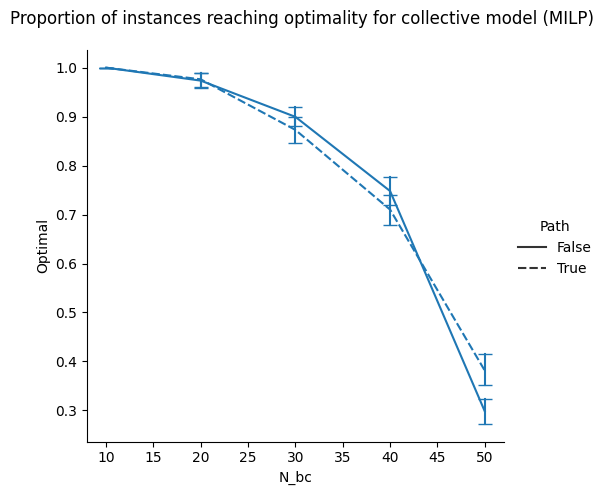

In [ ]:
g = sns.relplot(
    df_collective,
    x="N_bc",
    y=df_collective["Optimal"],
    # col="M",
    # row="Group_size",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle(
    "Proportion of instances reaching optimality for collective model (MILP)"
)
g

## Distance

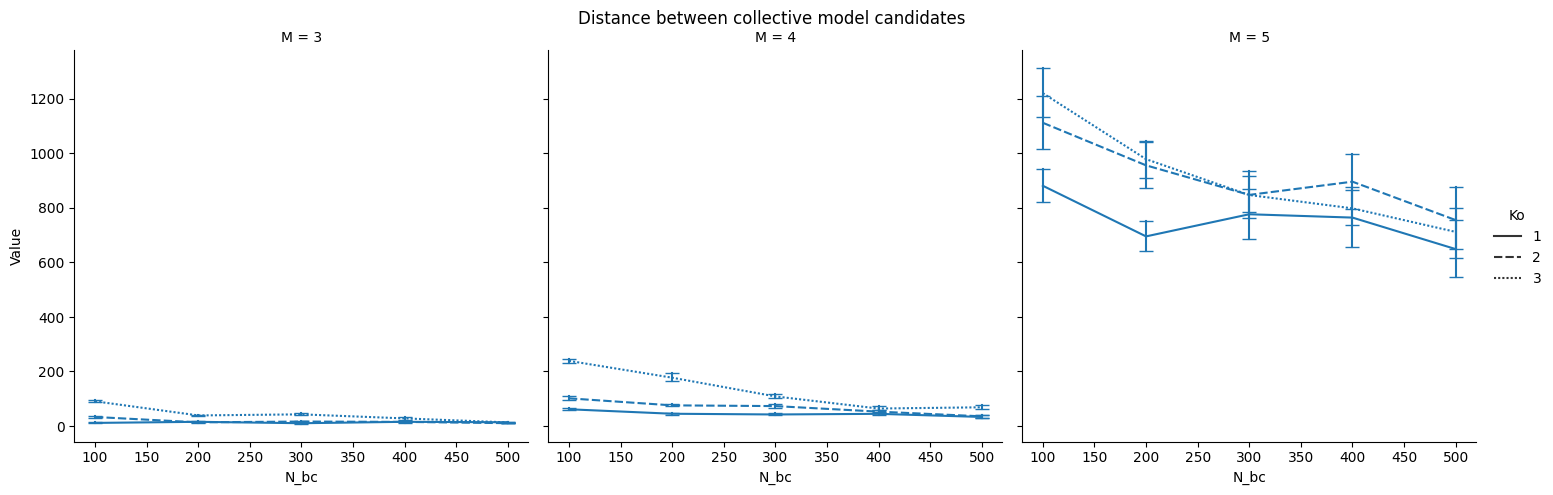

In [ ]:
g = sns.relplot(
    df_distance[df_distance["Time"] < 60],
    x="N_bc",
    y="Value",
    # row="Nb_Mcp",
    col="M",
    style="Ko",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Distance between collective model candidates")
g
tikzplotlib.save("mytikz.tex", standalone=True)

## Path optimal

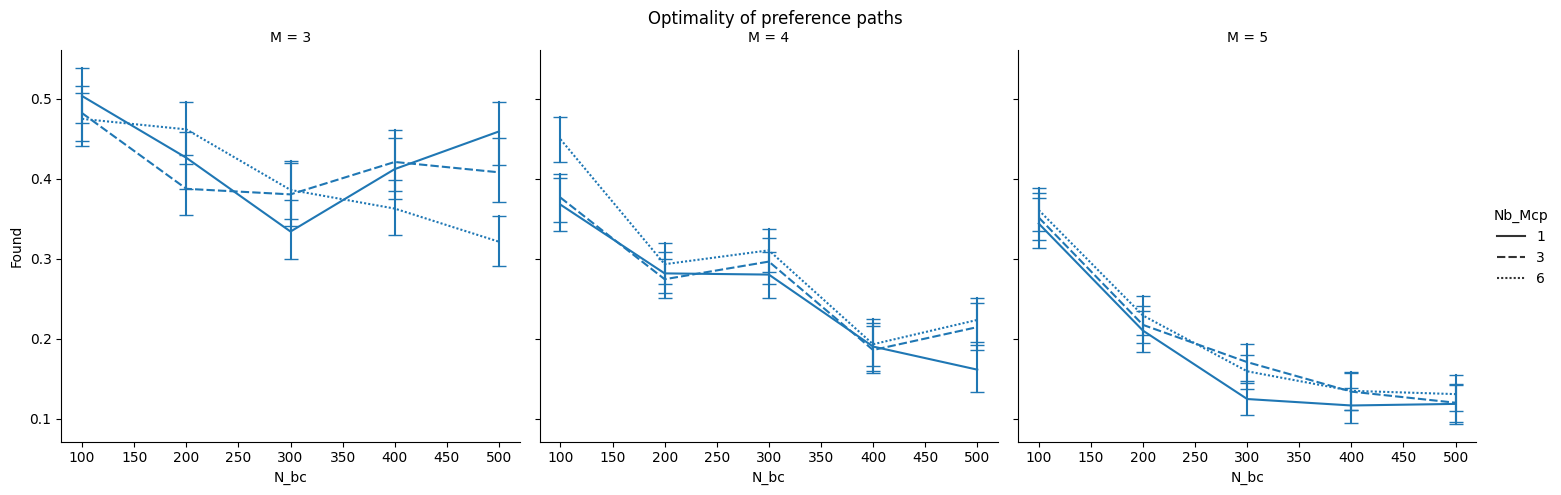

In [ ]:
g = sns.relplot(
    df_path[df_path["Length"] > 0],
    x="N_bc",
    y="Found",
    # row="M",
    col="M",
    style="Nb_Mcp",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Optimality of preference paths")
g

## Computing time

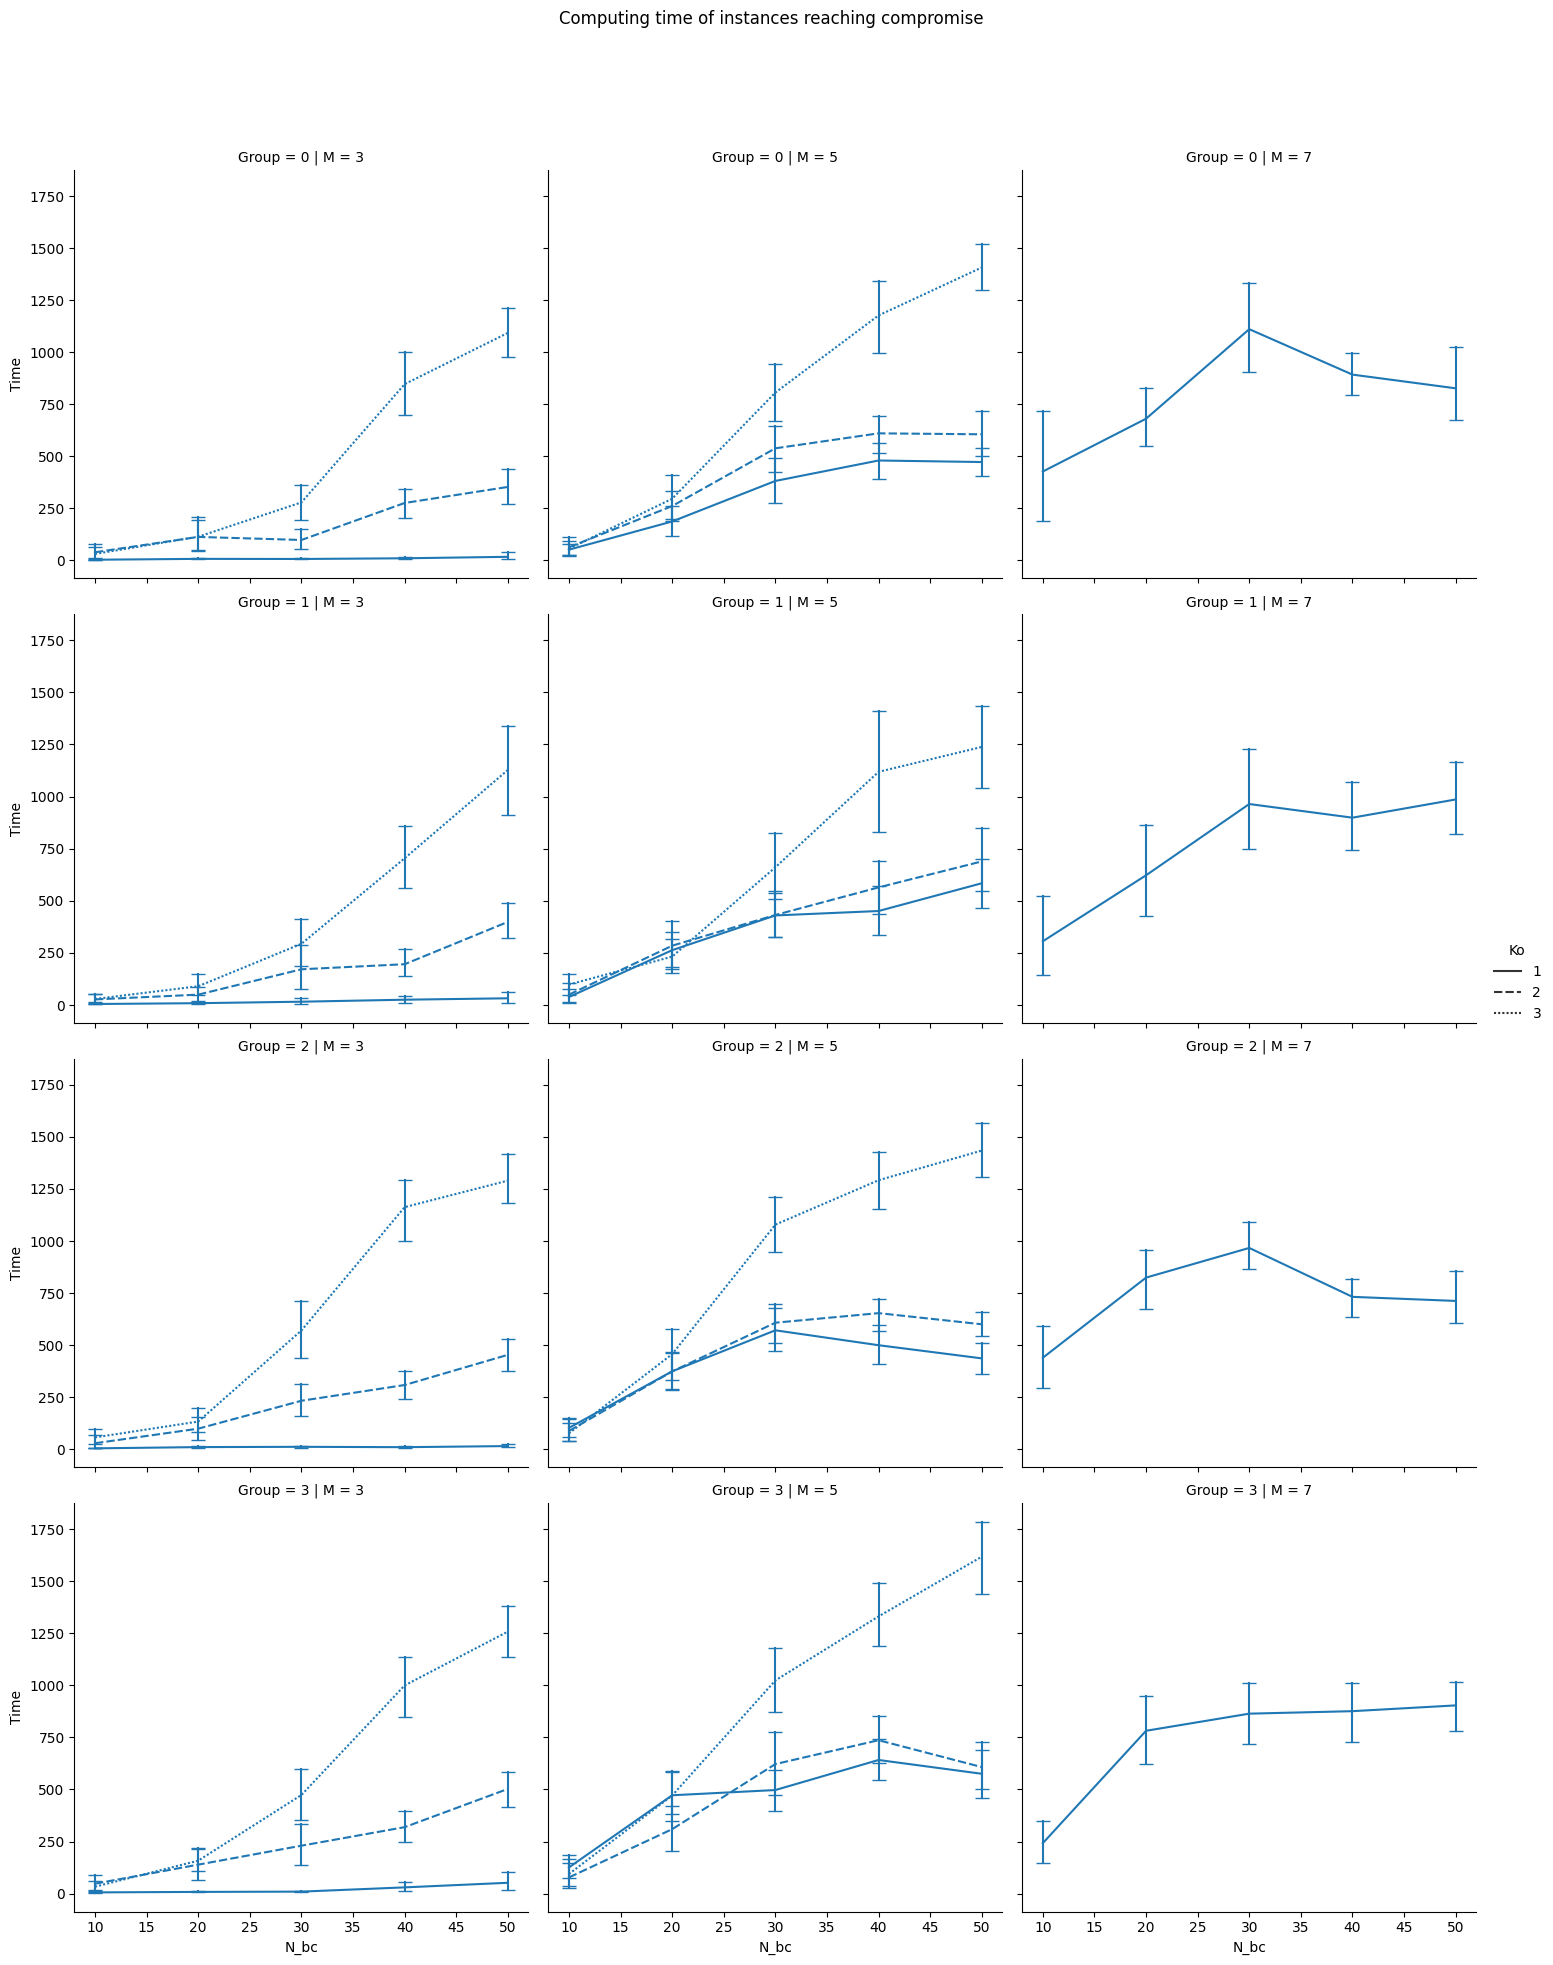

In [42]:
g = sns.relplot(
    dff,
    x="N_bc",
    y="Time",
    row="Group",
    col="M",
    style="Ko",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Computing time of instances reaching compromise")
g

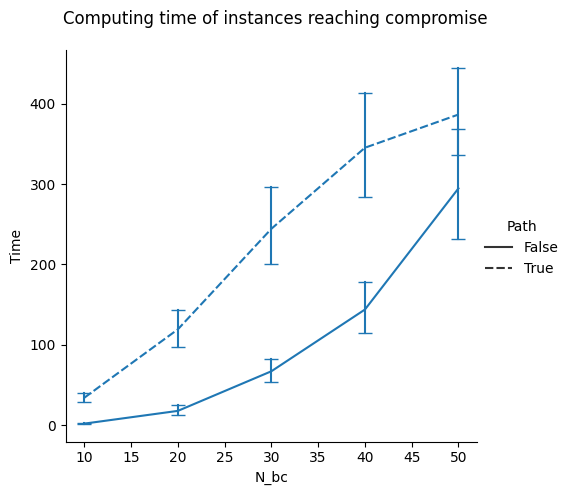

In [ ]:
g = sns.relplot(
    dff[dff["Compromise"]],
    x="N_bc",
    y="Time",
    # row="Group_size",
    # col="M",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Computing time of instances reaching compromise")
g

## Computing time per it

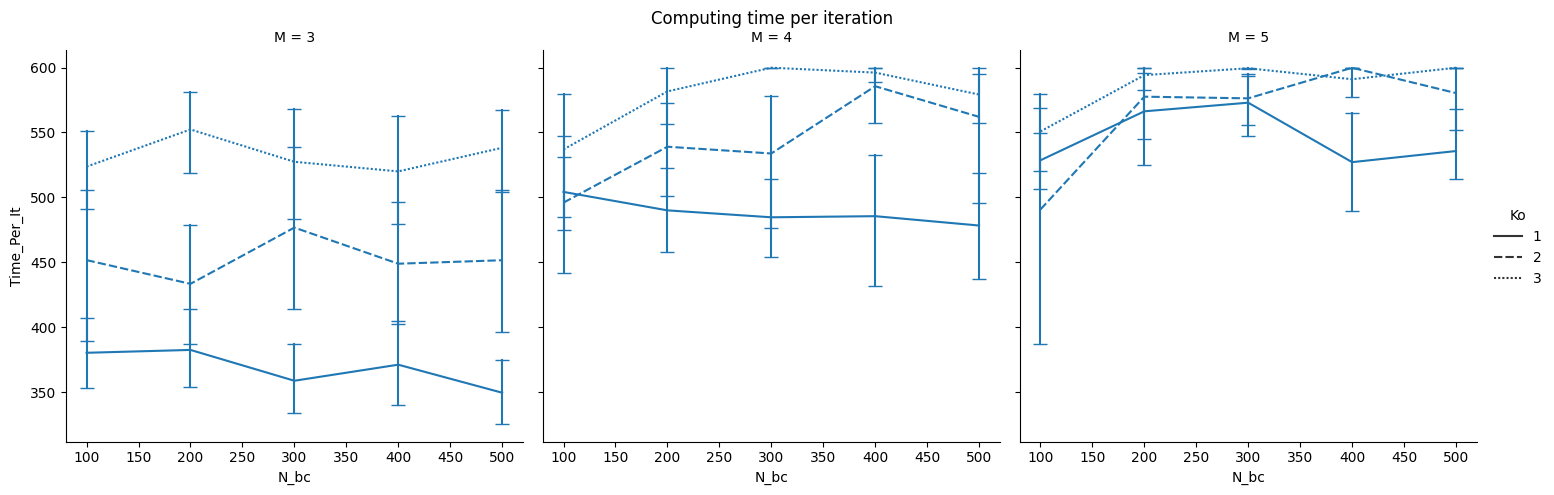

In [ ]:
g = sns.relplot(
    dff,  # [dff["Compromise"]],#[dff["Ko"] == 2],# & (~ dff["Path"]) & (dff["Group"] == "Homo")],
    x="N_bc",
    y="Time_Per_It",
    # row="M",
    col="M",
    style="Ko",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Computing time per iteration")
g

tikzplotlib.save("mytikz.tex", standalone=True)

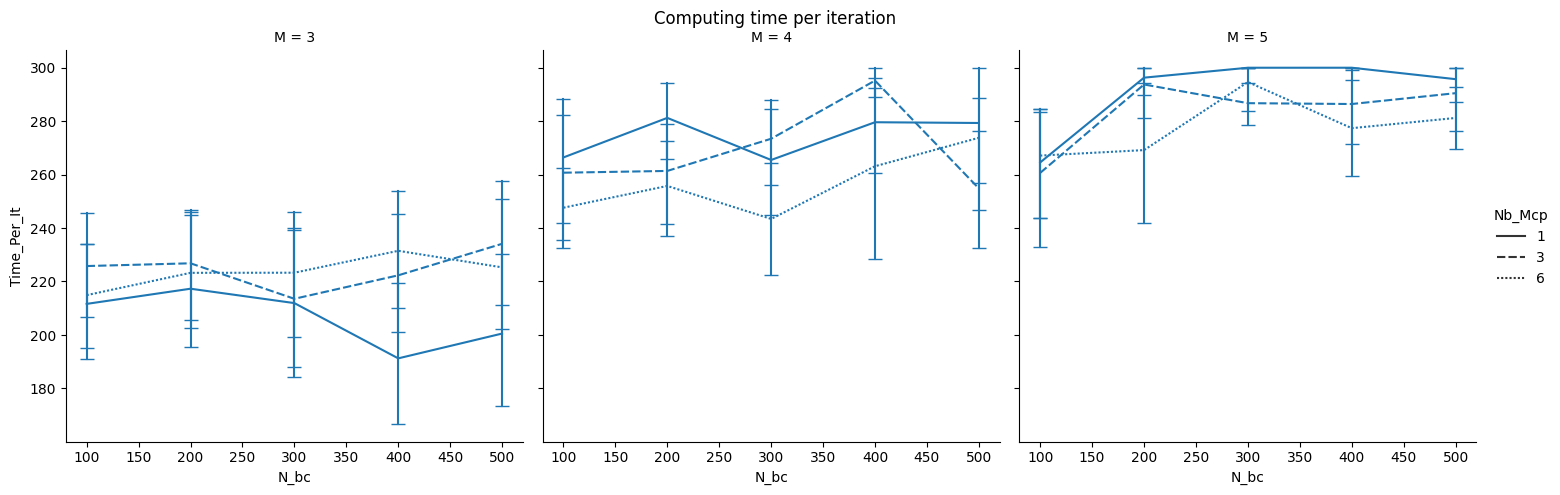

In [ ]:
g = sns.relplot(
    dff,  # [dff["Compromise"]],#[dff["Ko"] == 2],# & (~ dff["Path"]) & (dff["Group"] == "Homo")],
    x="N_bc",
    y="Time_Per_It",
    # row="M",
    col="M",
    style="Nb_Mcp",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Computing time per iteration")
g

tikzplotlib.save("mytikz.tex", standalone=True)

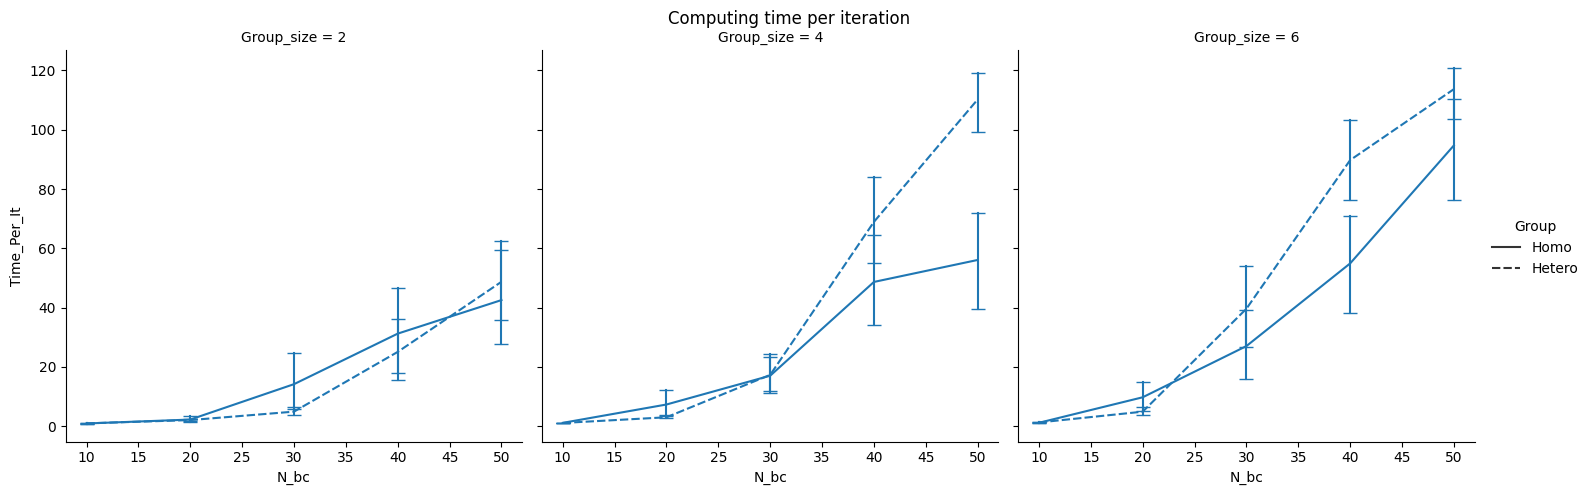

In [ ]:
g = sns.relplot(
    dff[dff["Compromise"] & (~dff["Path"]) & (dff["Ko"] == 2)],
    x="N_bc",
    y="Time_Per_It",
    # row="Group",
    col="Group_size",
    style="Group",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Computing time per iteration")
g

tikzplotlib.save("mytikz.tex", standalone=True)

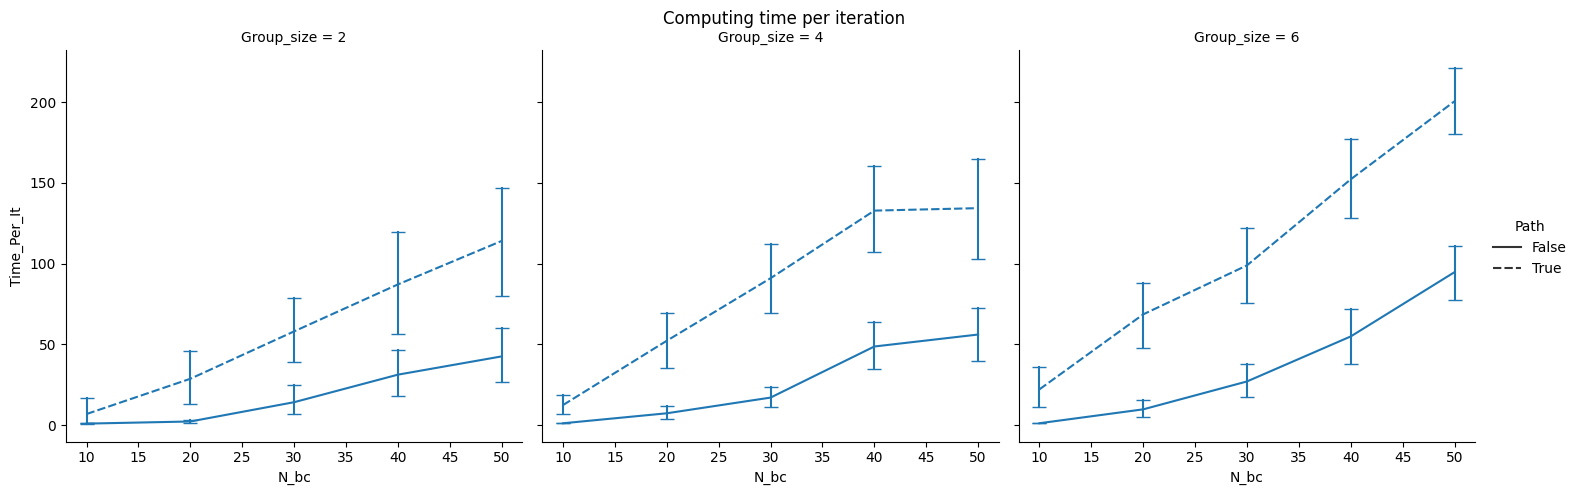

In [ ]:
g = sns.relplot(
    dff[dff["Compromise"] & (dff["Group"] == "Homo") & (dff["Ko"] == 2)],
    x="N_bc",
    y="Time_Per_It",
    # row="Group_size",
    col="Group_size",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Computing time per iteration")
g

tikzplotlib.save("mytikz.tex", standalone=True)

## MILP computing time

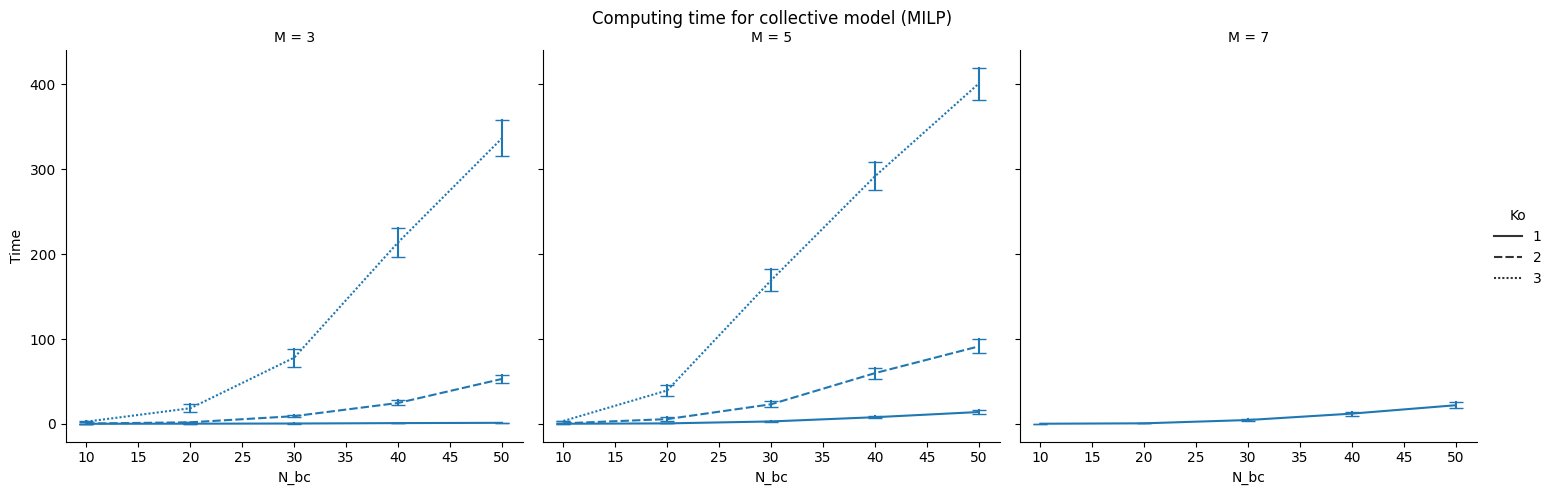

: 

In [ ]:
g = sns.relplot(
    df_collective,
    x="N_bc",
    y="Time",
    # row="Group_size",
    col="M",
    style="Ko",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Computing time for collective model (MILP)")
g

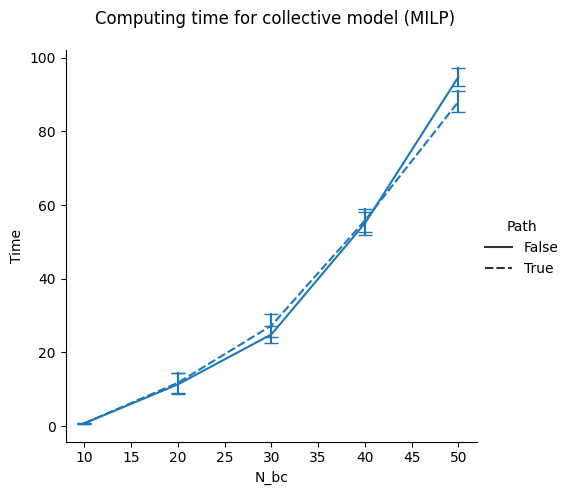

In [ ]:
g = sns.relplot(
    df_collective,
    x="N_bc",
    y="Time",
    # row="Group_size",
    # col="M",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Computing time for collective model (MILP)")
g

## Preference path computing time

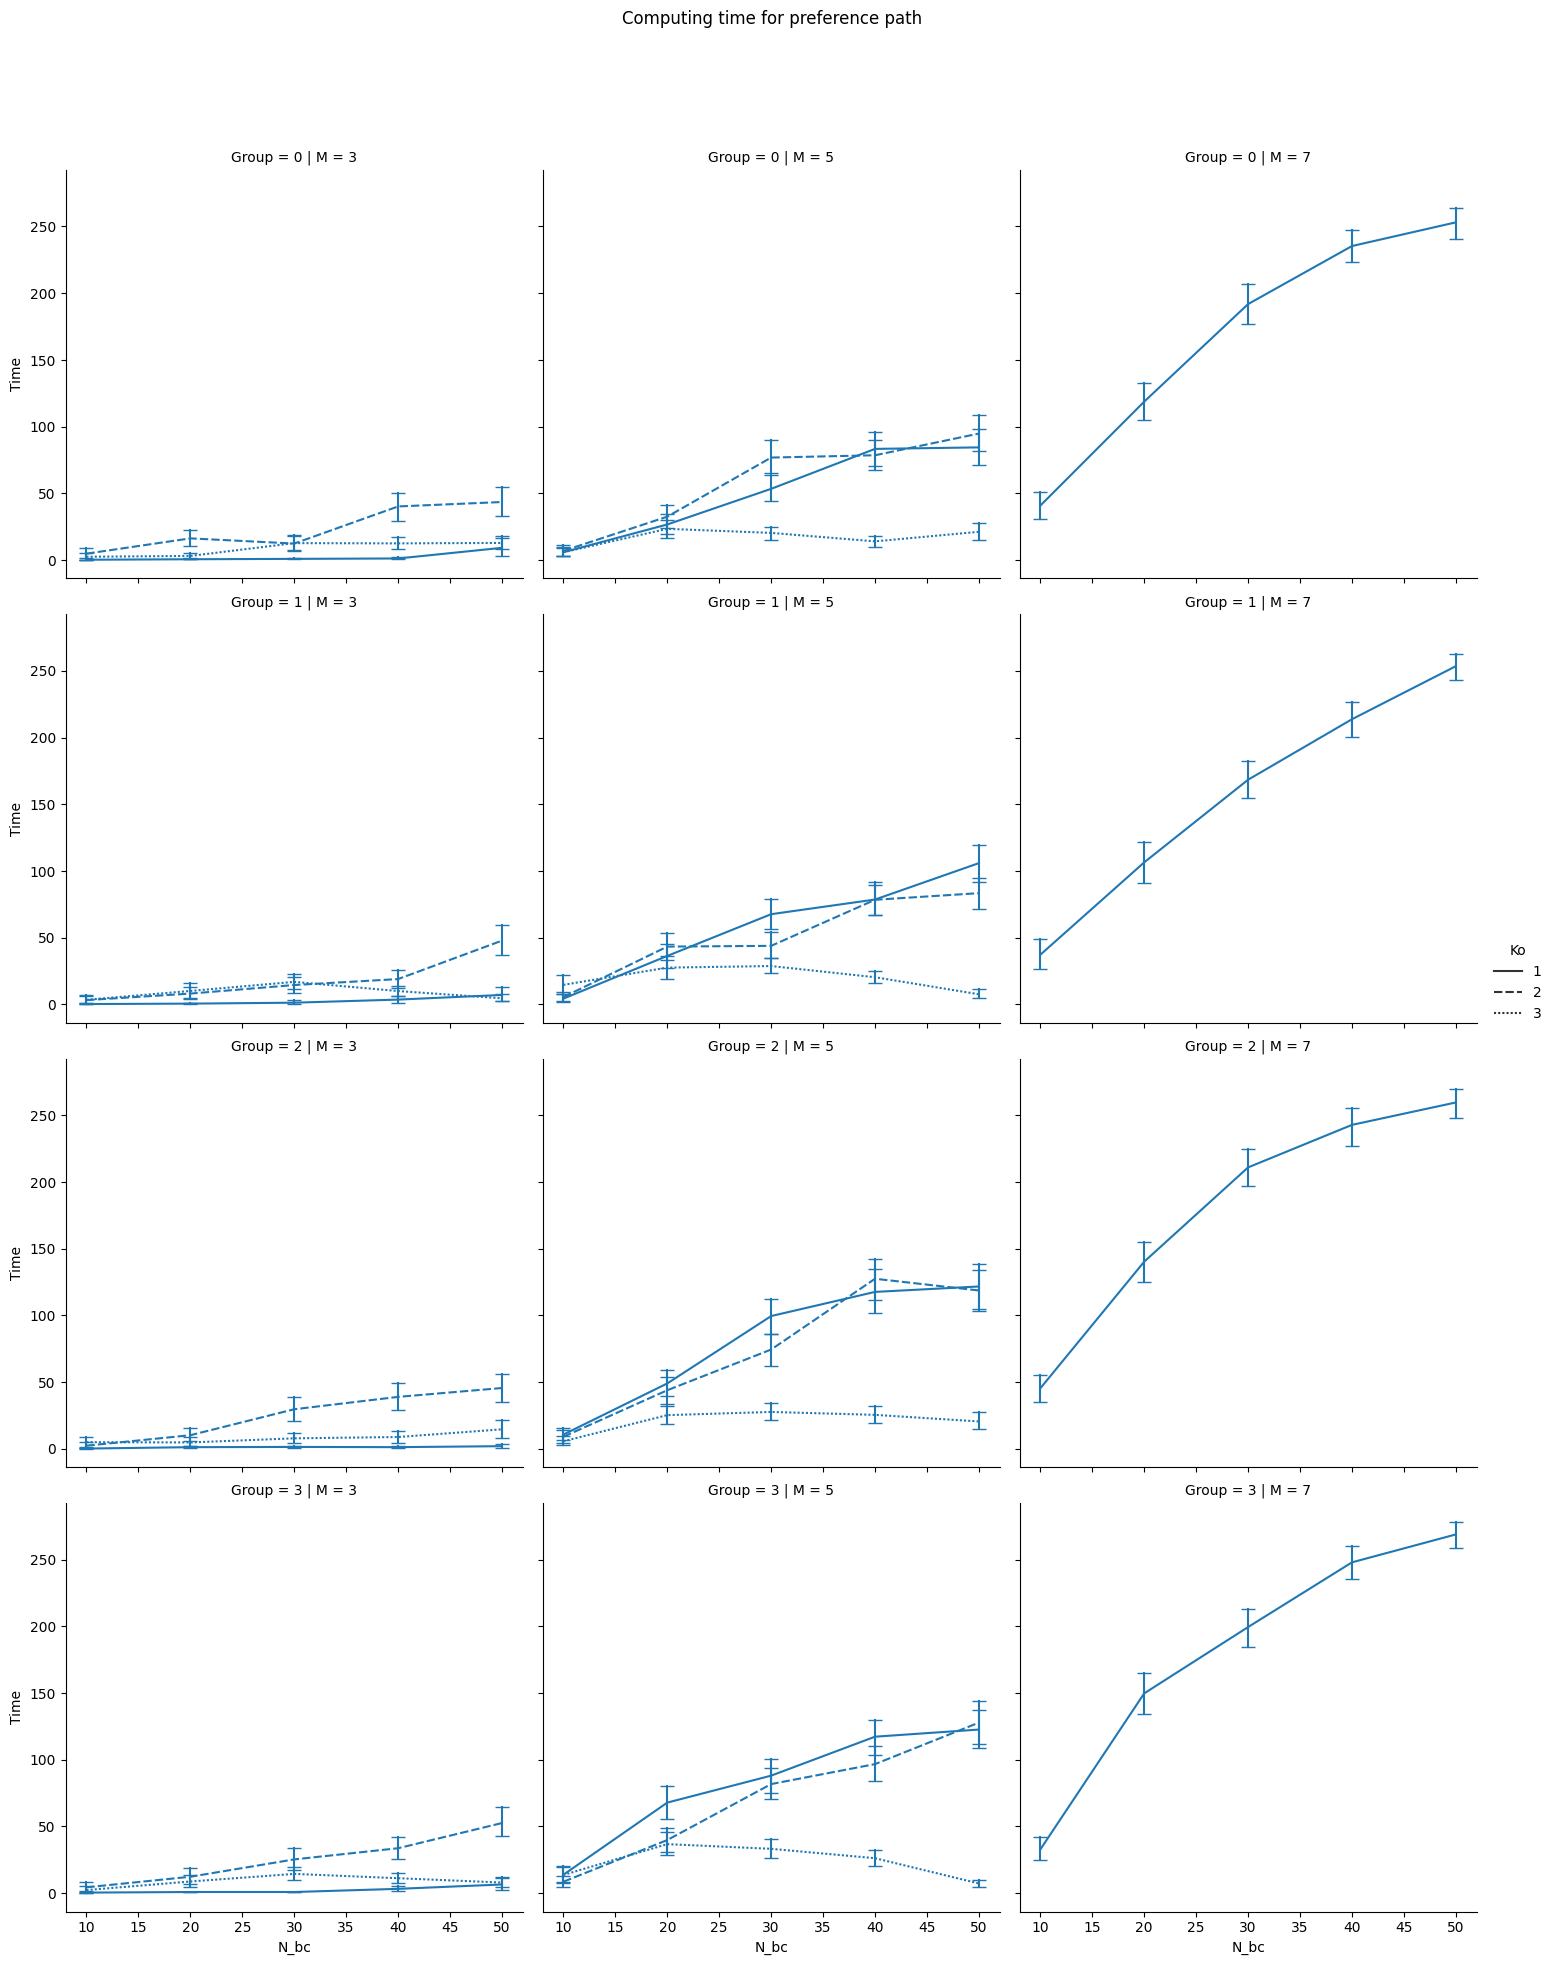

In [43]:
# (df_path["Found"])
g = sns.relplot(
    df_path,#[(df_path["Found"])],
    x="N_bc",
    y="Time",
    col="M",
    row="Group",
    style="Ko",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Computing time for preference path")
g

## Iterations

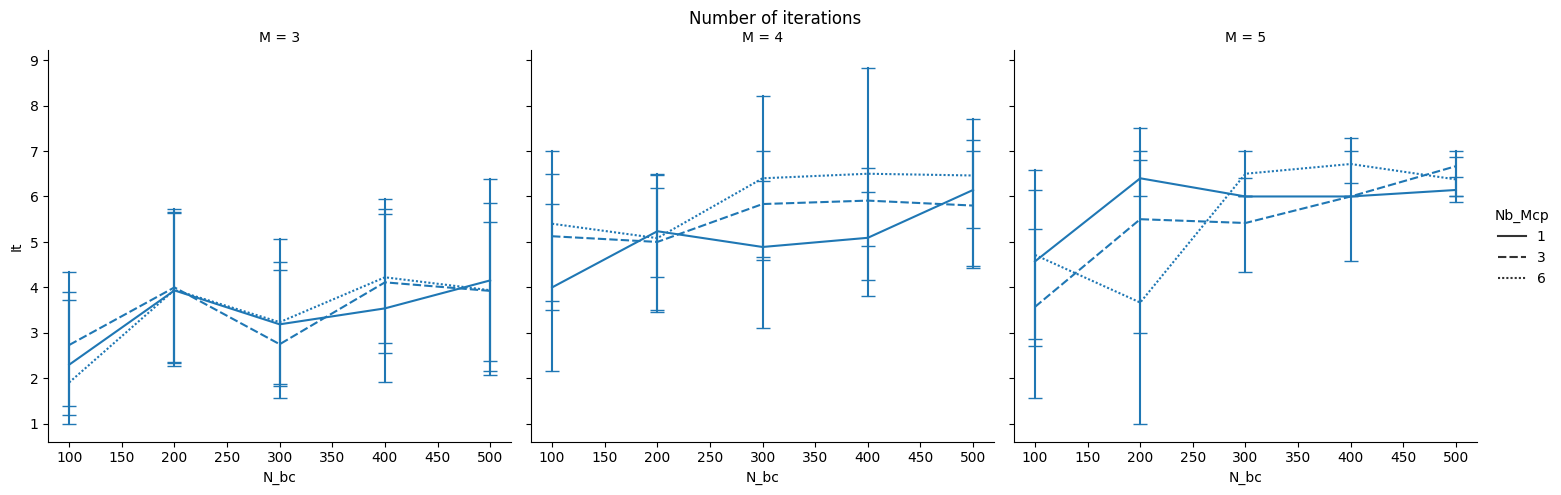

In [ ]:
g = sns.relplot(
    # dff[dff["Compromise"] & (~dff["Path"]) & (dff["Group"] == "Homo")],
    dff,
    x="N_bc",
    y="It",
    # row="M",
    col="M",
    style="Nb_Mcp",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Number of iterations")
g

tikzplotlib.save("mytikz.tex", standalone=True)

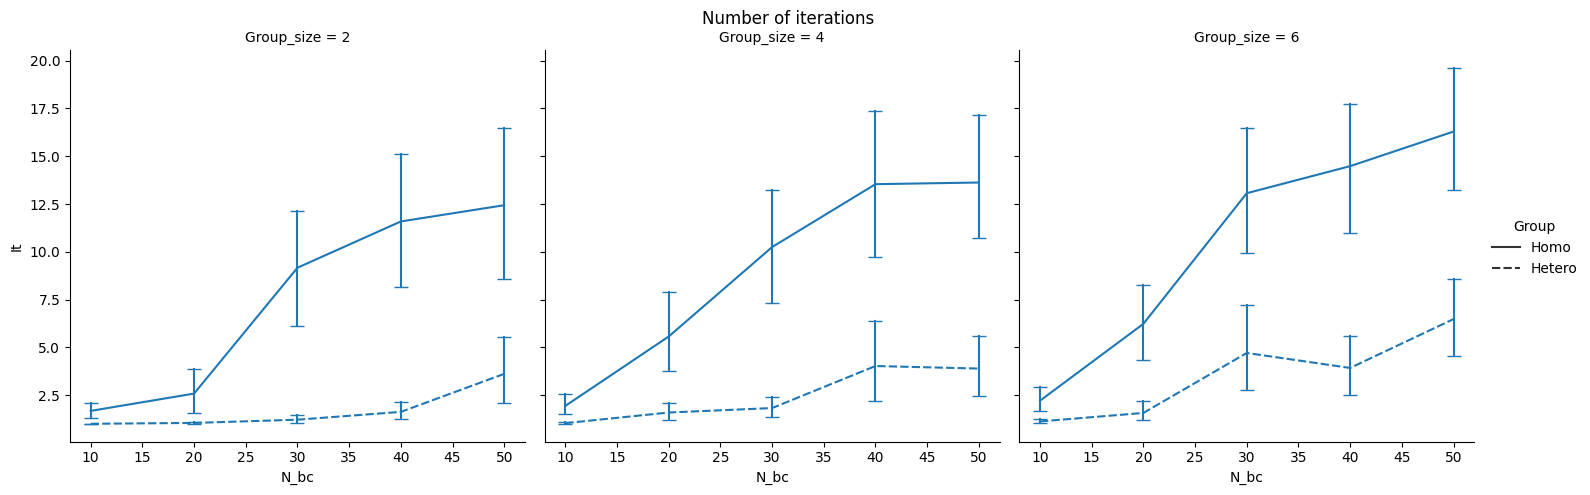

In [ ]:
g = sns.relplot(
    dff[(~dff["Path"])],
    x="N_bc",
    y="It",
    col="Group_size",
    # row="Group",
    style="Group",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Number of iterations")
g

tikzplotlib.save("mytikz.tex", standalone=True)

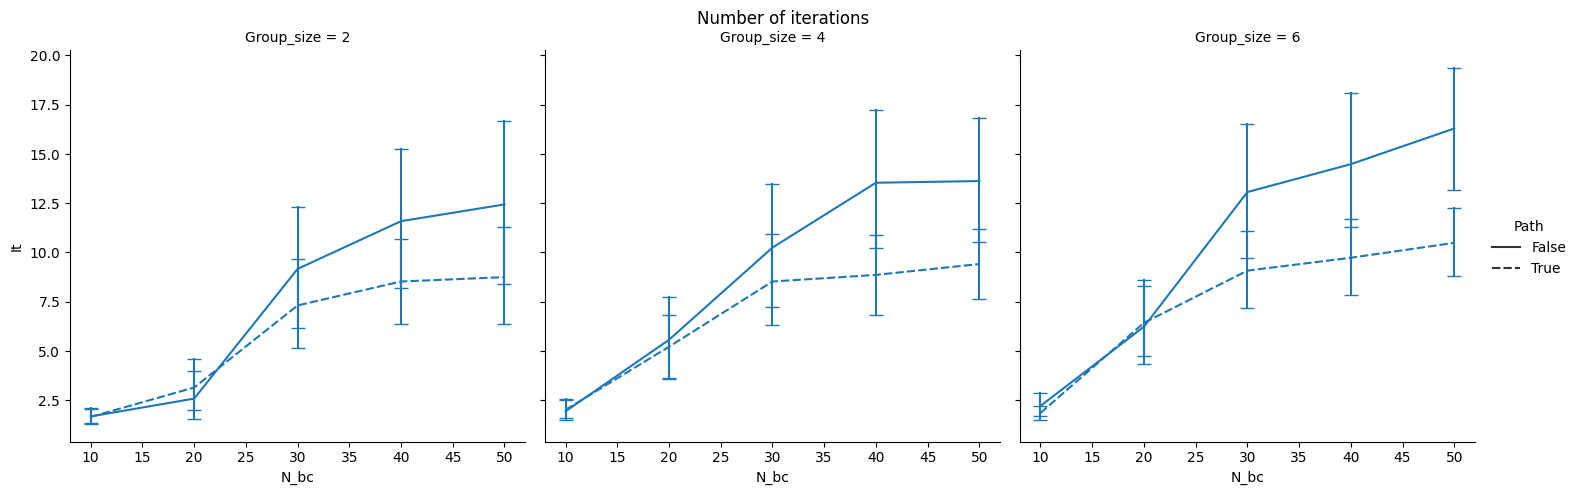

In [ ]:
g = sns.relplot(
    dff[(dff["Group"] == "Homo")],
    x="N_bc",
    y="It",
    col="Group_size",
    # row="Group",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Number of iterations")
g

tikzplotlib.save("mytikz.tex", standalone=True)

## Length of model preference paths

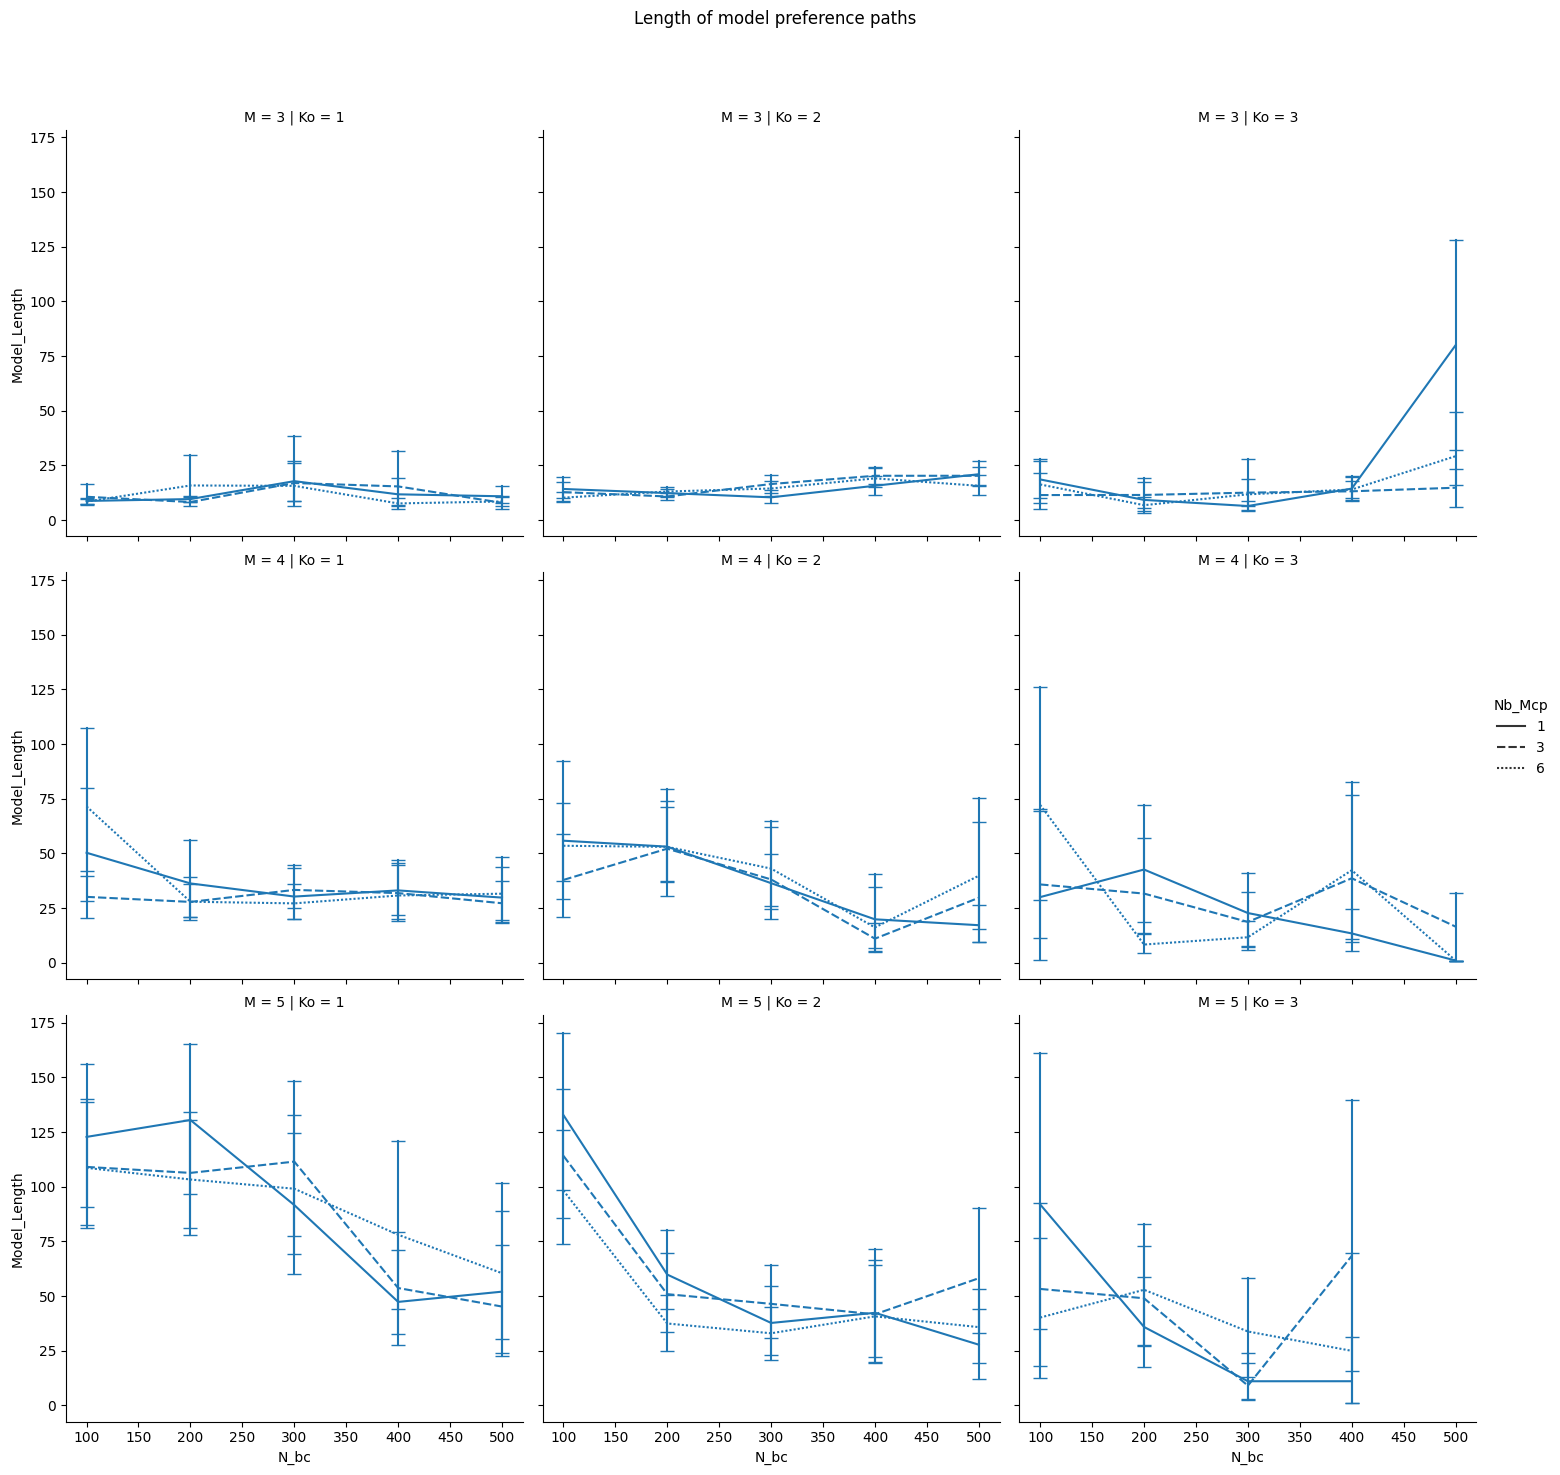

In [ ]:
g = sns.relplot(
    df_path[df_path["Length"] > 0],
    x="N_bc",
    y="Model_Length",
    row="M",
    col="Ko",
    style="Nb_Mcp",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Length of model preference paths")
g

## Length of preference paths

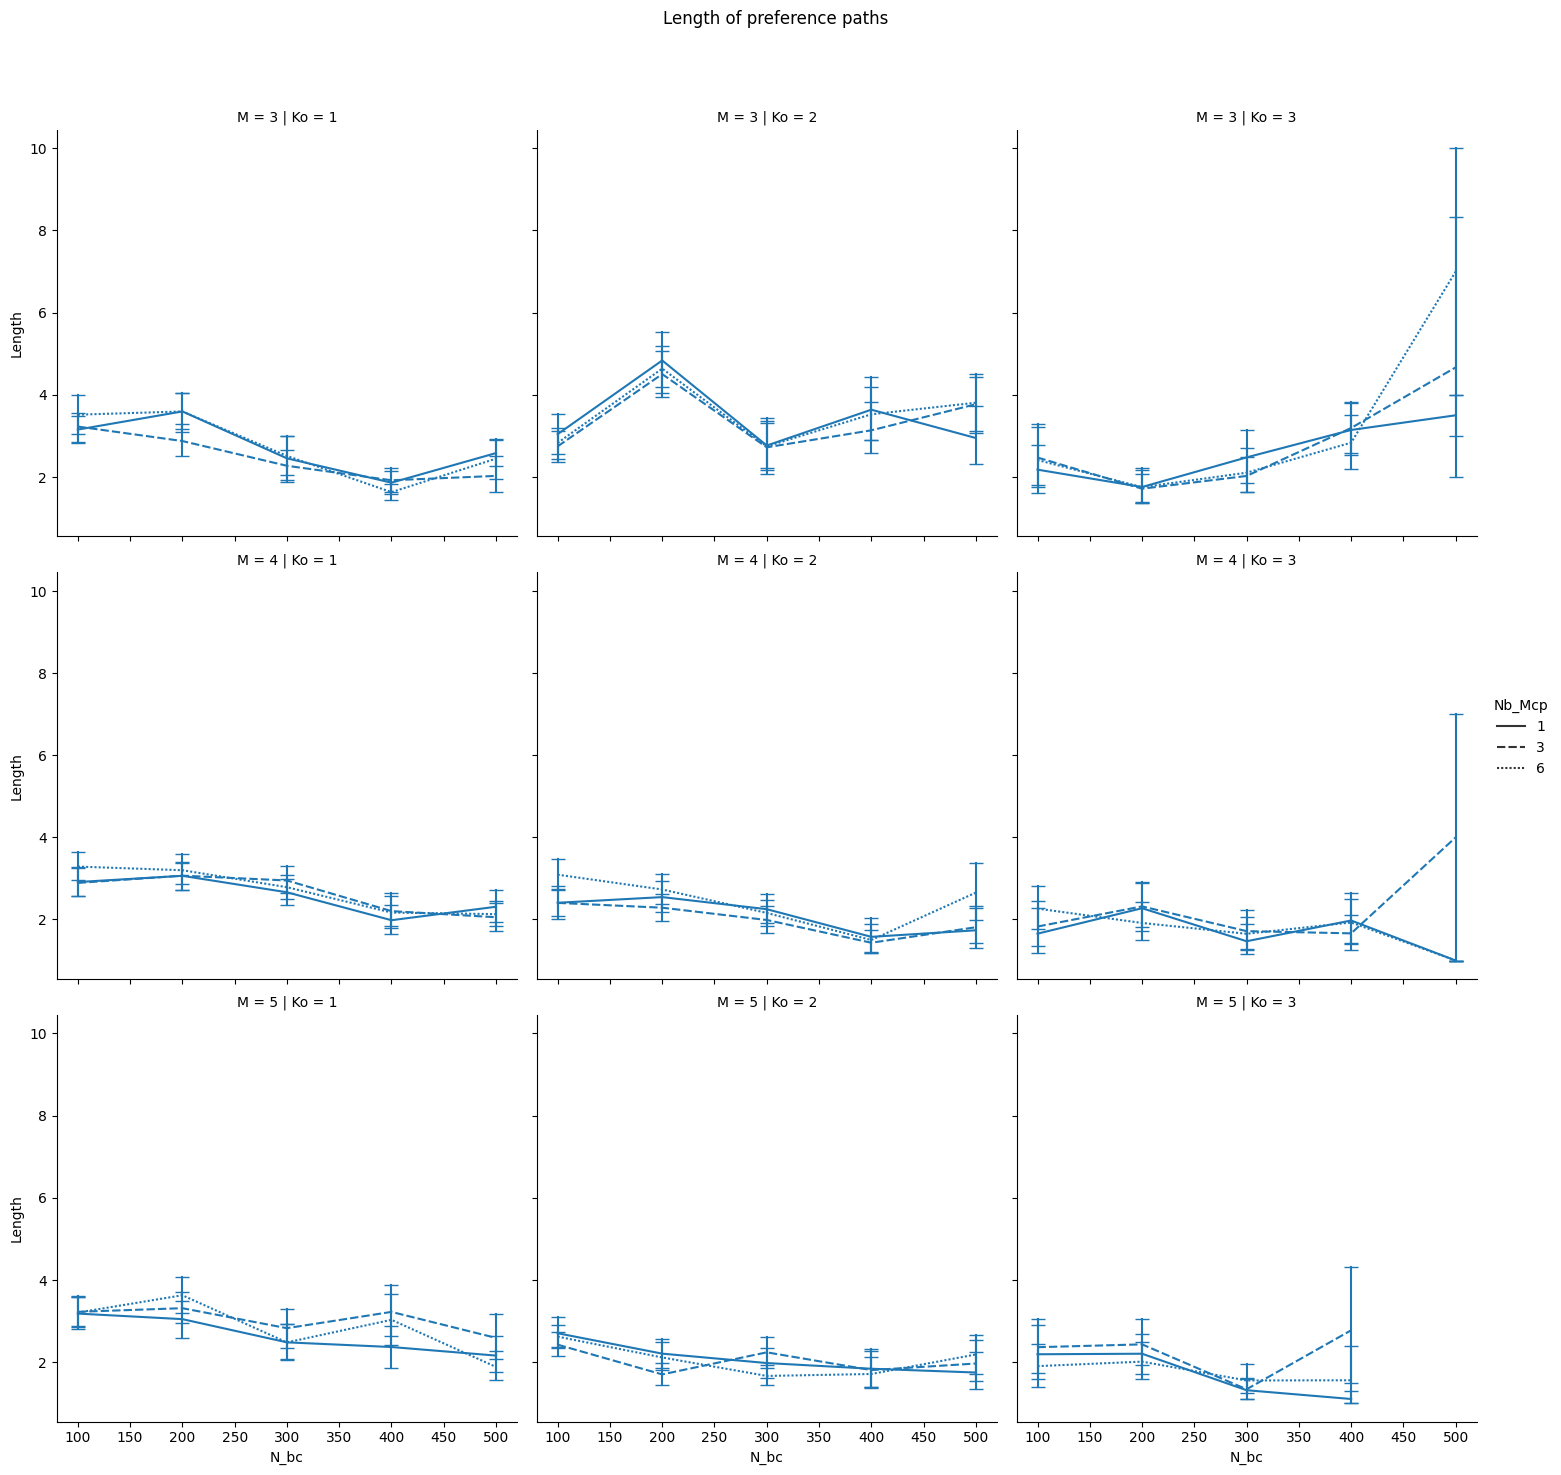

In [ ]:
g = sns.relplot(
    df_path[df_path["Length"] > 0],
    x="N_bc",
    y="Length",
    row="M",
    col="Ko",
    style="Nb_Mcp",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Length of preference paths")
g